# Multi-goal guidance

DynaGuide with **several goal steps in a fixed order**, like *open the drawer → grip the blue block → put it in the drawer → close the drawer*. Branch `Multigoal_guidance`.

Section 1 is the pipeline: what to run, in which order, to get from nothing to multi-goal rollouts. Sections 2 to 10 explain how it works and why; sections 11 to 13 are the experiments so far. Every number and plot below is computed from files in `results/` and `datasets/` when the notebook runs.

**Contents**

1. The pipeline: from nothing to multi-goal rollouts
2. Why one goal isn't enough
3. What changed where
4. The experiment config: `goal_sequence`
5. The environment's side: `SequentialGoalTracker`
6. Goal checks for blocks
7. DynaGuide's side: guidance per step and the switch
8. Testing the switch
9. The oracle switch (ablation)
10. Base sets and tasks: how the conditions are made
11. First rollouts: drawer and block with debug-set conditions
12. One block, one scene: open → grip → release → close
13. Why the robot doesn't grip: a check of DynaGuide itself
14. Limitations and next steps

## 1. The pipeline: from nothing to multi-goal rollouts

### Info

```
1.1 base sets (once)       recombine_conditions.py --hide_blocks, extract_block_poses.py  ->  datasets/robot_poses/
1.2 task file              calvin_exp_configs_examples/tasks/<task>.json                  (you write it: reset + steps)
1.3 make the task          make_task.py                                                    ->  datasets/guidance_conditions/<task>/
1.4 plan                   calvin_exp_configs_examples/multigoal/plan_<name>.json          (you write it: which configs, how many rollouts)
1.5 rollouts               run_experiments.py                                              ->  results/<name>/
1.6 results                summary.json, the logs and videos of each run, evaluate_behaviors.py
```

**Where to run it.** All commands run from `DynaGuide-main`.
- **MacBook (CPU):**
  ```bash
  conda activate ml
  export PYTHONPATH=$PWD/robomimic:$PWD/calvin/calvin_env:$PWD
  ```
  Guided rollouts take about 1 s per env step, so only short tests run here.
- **Workstation:** `conda activate dynaguide`, then one `.bat` script per experiment runs steps 1.1 to 1.5 (section 1.7).

**Needed, but not in git** (everything in `datasets/`, `results/` and every `*.pth` is git-ignored):

| What | Needed for |
|---|---|
| `base_policy_300.pth`, `dynamics_model_5900.pth` in `DynaGuide-main` | the rollouts |
| `datasets/robot_poses/` (`articulated`, `blocks`; about 310 MB) | making tasks. Copy it to another machine rather than rebuilding it there: a rebuild also collects poses from that machine's own `results/` and comes out different |
| `datasets/calvin_debug_dataset`, `datasets/guidance_conditions/debug_all`, `button_pressed` | only for building the base sets (1.1) |

### 1.1 Base sets of robot poses (once)

The base sets are robot poses at a goal, rendered in every combination of the other joints. Section 10 explains them. They are made once. Skip this step when `datasets/robot_poses/articulated` and `datasets/robot_poses/blocks` exist.

```bash
python dynaguide_scripts/recombine_conditions.py --hide_blocks --output_folder datasets/robot_poses/articulated
```
- **What it does:** takes the robot at the goal of each condition in `debug_all` (drawer, door, switch) and `button_pressed` (button), removes all blocks, and renders it with every combination of the other joints. About 30 s.
- **Output:** `articulated/<behavior>/<scene>.hdf5`, 8 scenes per behavior, and `<behavior>_all_no_blocks.png` with all of them.

```bash
python dynaguide_scripts/extract_block_poses.py --sources datasets/calvin_debug_dataset/validation datasets/calvin_debug_dataset/training \
    datasets/guidance_conditions results --output_folder datasets/robot_poses/blocks
```
- **What it does:** finds every moment where a block is gripped or let go of, on the table, in the drawer or in the cabinet. It searches the debug recordings, all condition files and all rollouts, and drops duplicates. Then it renders each pose with the blue block in every scene. About 4 min.
- **Output:** `blocks/poses/<kind>.hdf5` (the poses as found) and `blocks/<kind>/<action>_<side>/<scene>.hdf5`, e.g. `blocks/grip_table/grip_right/`, each with `<action>_<side>_all.png`.

Look at the `*_all.png` images before going on.

### 1.2 Write a task file

A task is the reset and the goal steps, in `calvin_exp_configs_examples/tasks/<task>.json`. This is `blue_table_to_open_drawer.json`:

```json
{
    "env_setup": {"drawer": 0.2, "sliding_door": "left", "switch": "off", "green_light": "off",
                  "blocks": {"blue": {"place": "table_right", "offset": [0.0, -0.03], "yaw": 0.0}, "red": "hidden", "pink": "hidden"}},
    "reset_poses": "calvin_exp_configs_examples/reset_poses/initial_calvin_robot_states_right_side_midpoint.json",
    "block": "blue",
    "max": 12,
    "steps": [
        {"name": "grip_blue", "poses": "blocks/grip_table/grip_right", "contrast_poses": "articulated/drawer_open", "scale": 1.5, "alpha": 30},
        {"name": "release_blue_in_drawer", "poses": "blocks/release_drawer", "scale": 1.5, "alpha": 30}
    ]
}
```

| Key | Meaning |
|---|---|
| `env_setup` | the reset. **Every** joint and block must be fixed (a spot like `table_right` with `yaw`, or `"hidden"`), so every rollout starts in the same scene and the conditions can show exactly that scene |
| `reset_poses` | where the robot starts, as in any experiment config |
| `block` | the block the task works with; block poses are recolored to it |
| `max` | at most this many conditions per step, spread over the poses |
| step `poses` | the base set of the step: `articulated/<behavior>` or `blocks/<kind>[/<action>_<side>]` |
| step `contrast_poses` | the switch's contrast for this step (usually only the first; later steps contrast with the step before) |
| step `behaviors` / `where` | what the env checks. Left out, it follows from `poses`: `drawer_open`, block `held`, block in the drawer and released, … |
| step `scale`, `alpha`, `switch`, `max_steps`, … | copied into the experiment config. Without `scale` / `alpha`, the plan's values are used |
| step `near`, `max`, `block_after` | only block poses this close to the block; a per-step cap; where the block lies after a release (default: the center of the area) |

The steps must fit the story. A grip needs the block resting in the area of its poses, and a drawer pose needs the drawer open at that step. `make_task.py` stops with an error otherwise.

### 1.3 Make the task

```bash
python dynaguide_scripts/make_task.py --task calvin_exp_configs_examples/tasks/blue_table_to_open_drawer.json
```
- **What it does:** follows the task step by step. For each step it takes the base file of the scene the robot meets at that step, and renders every condition again: the reset's exact joint values, the task's block where the story has it, the robot of the pose. A few seconds.
- **Output** in `datasets/guidance_conditions/<task>/`:
  - `<step>.hdf5` and `<step>.png` per step, `<step>_contrast.hdf5` for a step with `contrast_poses`;
  - for the switch (section 7): `<step>_before.hdf5`, for a release step also `<step>_switch.hdf5`;
  - `<task>_all.png`, the first conditions of every step, labeled with the scene at that step. **Look at it**;
  - `manifest.json`, every condition and every skipped pose with the reason;
  - `experiment.json`, the experiment config with the reset and the `goal_sequence`, pointing to the condition files.
- **Changing a task file:** delete its folder and make it again. The scripts skip a task whose `experiment.json` exists, and a run would silently use the old conditions.

### 1.4 Write a plan

A plan lists the experiments, their variants and how many rollouts each gets. This is `calvin_exp_configs_examples/multigoal/plan_blue_table_to_open_drawer.json`, shortened:

```json
{
    "n_rollouts": 20, "horizon": 500, "scale": 1.5, "ss": 4, "alpha": 30, "base_policy": false,
    "experiments": {
        "two_steps": {"config": "datasets/guidance_conditions/blue_table_to_open_drawer/experiment.json",
                      "switch_variants": {"latent": {}, "oracle": {"mode": "oracle"}}, "seed": 0, "base_policy": true},
        "one_step":  {"config": "datasets/guidance_conditions/blue_table_to_open_drawer_one_step/experiment.json",
                      "switch_variants": {"guided": {}}, "seed": 0}
    }
}
```

- **`config`:** the `experiment.json` from 1.3.
- **`switch_variants`:** one run per entry, each merged into the config's `switch`. `latent` is DynaGuide deciding by itself; `oracle` is the env telling it (section 9).
- **`seed`:** the same seed gives the same start scenes and robot poses in every run of the experiment, so the variants are comparable.
- **`base_policy`:** adds a run without guidance. Per experiment it overrides the plan's value, so it runs once for experiments that share their start scenes.
- **Per experiment:** an experiment can also set `scale`, `ss` and `alpha`, as in `plan_grip_scale_sweep.json`.

### 1.5 Run the rollouts

```bash
python dynaguide_scripts/run_experiments.py --plan calvin_exp_configs_examples/multigoal/plan_blue_table_to_open_drawer.json \
    --output_folder results/blue_table_to_open_drawer --dry_run
```
- **What it does:** lists the runs and checks that every config, condition file and reset-pose file exists, without running anything.

```bash
python dynaguide_scripts/run_experiments.py --plan calvin_exp_configs_examples/multigoal/plan_blue_table_to_open_drawer.json \
    --output_folder results/blue_table_to_open_drawer --agent base_policy_300.pth --guidance dynamics_model_5900.pth
```
- **What it does:** runs every run as its own `run_dynaguide.py` process and prints a status line every 2 minutes.
- **Stopping:** a failed run doesn't stop the others. After Ctrl+C, the same command continues where it stopped.

**One config without a plan**, e.g. to watch a single run:
```bash
python dynaguide_scripts/run_dynaguide.py --agent base_policy_300.pth --guidance dynamics_model_5900.pth \
    --exp_setup_config datasets/guidance_conditions/blue_table_to_open_drawer/experiment.json --output_folder results/my_run \
    --n_rollouts 2 --horizon 200 --camera_names third_person --video_skip 2 --no_collage --no_live_render --scale 1.5 --ss 4 --alpha 30
```

### 1.6 Read the results

`results/<name>/` holds:
- `summary.json`, the table of all runs printed at the end;
- per run, `<experiment>/<variant>/` with `config.json` (the config it ran with, including the condition files), `*_rollout.hdf5`, `*_video.mp4` (the current step is written on the video), `console.txt` and `*_log.json`.

The keys of `*_log.json`:

| Key | Meaning |
|---|---|
| `Success_Rate`, `Num_Success` | episodes in which every step completed |
| `Mean_Steps_Completed`, `Step_Reach_Rate` | how far the episodes got, per step |
| `Failures` | episodes ended by `avoid_behaviors` (with `on_avoid` `end`) or `max_steps` |
| `Violations`, `Num_Success_Without_Violation` | how often something to avoid happened, and the successes without any of it |
| `Episode_Goal_Steps` | per episode and step: when it started and completed, the events seen |
| `Switching` | latent switch per step: moved on, **too early** (before the env saw the step done), **missed**, delay |
| `Episode_Switches` | per episode: the switches and the trace of the switch score |

What to compare: oracle vs. base policy shows whether the guidance of the steps works at all; latent vs. oracle shows what the autonomous switch costs.

**Scoring rollouts again**, e.g. against another goal sequence than the one they ran with:
```bash
python dynaguide_scripts/evaluate_behaviors.py --dataset results/blue_table_to_open_drawer/two_steps/latent \
    --config datasets/guidance_conditions/blue_table_to_open_drawer/experiment.json
```

### 1.7 Scripts for the workstation and a test run

On the workstation each experiment has a `.bat` in `dynaguide_scripts\` that runs 1.1, 1.3 and 1.5. It skips what already exists, and continues the rollouts when started again.

| Script | What it runs |
|---|---|
| `setup_robot_poses.bat` | 1.1, only the base sets that are missing. The others call it first |
| `run_blue_table_to_open_drawer.bat` | grip the blue block, release it in the open drawer: two steps (latent, oracle), one step, base policy |
| `run_single_block_drawer.bat` | open the drawer, grip, release in the drawer, close: latent, oracle, base policy (section 12) |
| `run_goal_switch.bat` | the test of the goal switch (section 8): four chains of joint behaviors, new switch, oracle, previous switch |
| `run_goal_switch_patches.bat` | the same four chains with the `patches` criterion, plus its replay on recorded rollouts (section 8) |
| `run_grip_scale_sweep.bat` | grip only, base policy and guided at scale 1.5, 3 and 5 (section 13) |

**A test run on the MacBook** runs the whole pipeline once, from empty folders in `results/pipeline_test`, with 2 rollouts of 200 steps per run. It catches broken commands before the long run (about 25 min):
```bash
bash dynaguide_scripts/test_task_pipeline.sh
```

### 1.8 Tests

```bash
python -m pytest tests -m "not slow"   # 55 tests in about 10 s: goal tracking, block checks, switch, pose finding, task story, made tasks
python -m pytest tests                 # also the 2 tests that load the dynamics model, about a minute on the CPU
```
`tests/test_scene_conditions.py` also checks every task made in `datasets/guidance_conditions`: exactly one block in view, the block and the drawer as the story says at each step, door, switch and light as in the reset.

### 1.9 Optional: calibrating the switch

Only needed to re-check the older criteria (`peak`, `contrast`, …) of section 8. The current switch is tested with `run_goal_switch.bat`.
```bash
python dynaguide_scripts/render_recording_in_sim.py --recordings datasets/calvin_debug_dataset/validation --output datasets/calvin_debug_dataset_sim/validation.hdf5
```
- renders the debug validation recording in the simulator, so it has the rollouts' image style.

```bash
R=datasets/guidance_conditions/recombined_debug
python dynaguide_scripts/calibrate_goal_switching.py --guidance dynamics_model_5900.pth \
    --condition_sets "drawer_open=$R/drawer_open/*.hdf5" "drawer_close=$R/drawer_close/*.hdf5" "door_left=$R/door_left/*.hdf5" \
                     "door_right=$R/door_right/*.hdf5" "switch_on=$R/switch_on/*.hdf5" "switch_off=$R/switch_off/*.hdf5" \
    --exclude_sources validation --evaluate datasets/calvin_debug_dataset_sim/validation.hdf5 --output results/multigoal_calibration_sim
```
- the **sim setup** of section 8: the switch scores on the rendered recording, with conditions that don't come from it.

```bash
python dynaguide_scripts/calibrate_goal_switching.py --guidance dynamics_model_5900.pth --conditions datasets/calvin_debug_dataset/training \
    --evaluate datasets/calvin_debug_dataset/validation --output results/multigoal_calibration
```
- the **dataset setup** of section 8, for comparison.

With `--analyze_only`, both evaluate other switch settings from the saved distances without embedding again.

## 2. Why one goal isn't enough

With one experiment config, DynaGuide gets **one set** of guidance conditions (`pos_examples`, maybe several files) and guides towards all of them at once. The guidance is a soft nearest neighbour over the conditions (see `Dynamics model guidance.md`): the robot is pulled towards whichever condition is closest to its predicted outcome. Several conditions are therefore an **OR**, not a sequence.

That rules out tasks whose steps contradict each other or depend on each other:

- *open the drawer, then close it*: the drawer can't be open and closed at once. With both sets of conditions, the robot is pulled towards whichever it is already closer to, usually the closed drawer it starts with.
- *open the drawer, put the block in, close it*: the block-in-drawer conditions are far away at the start, the robot first has to open the drawer. The final state (closed drawer, block invisible inside) doesn't even show the block.

The environment had the same limit: `GoalTracker` scores the behaviors relative to the start of the episode, so it can't see "opened and later closed".

## 3. What changed where

| Part | File | What |
|---|---|---|
| Env: scoring the steps | `core/goal_sequence.py` (new) | `goal_sequence` config, validation, `SequentialGoalTracker`, statistics, scoring saved rollouts |
| Env: detecting behaviors | `core/calvin_behaviors.py` | `detect_behaviors` shared by both trackers; new events `red_lift`, `blue_lift`, `pink_lift` |
| Env: block goal checks | `core/guidance_conditions.py` | more block words, lists of words, `near`, `on`; `state_matches` for one state |
| DynaGuide: guidance and switch | `core/multigoal_guidance.py` (new) | `MultiGoalGuidance` (guides with the current step), `change_score`, `patches_score` and `SwitchCriterion` (latent switch), oracle switch |
| DynaGuide: speed | `core/dynaguide.py`, `core/dynamics_models.py` | the DINO patches of the current image are computed once per action chunk instead of 40 times (same gradient, tested); runs on CPU without CUDA |
| Rollouts | `dynaguide_scripts/run_dynaguide.py` | multi-goal mode: tracker, switching, replanning, video label, results json |
| Plans | `dynaguide_scripts/run_experiments.py` | `switch_variants` (e.g. latent vs. oracle), base policy for multi-goal configs |
| Scoring | `dynaguide_scripts/evaluate_behaviors.py` | scores rollout files of multi-goal configs step by step |
| Testing the switch | `dynaguide_scripts/test_goal_switch.py` (new) | what the switch did in rollouts, and the switch replayed over recorded ones, see section 8 |
| Calibration | `dynaguide_scripts/calibrate_goal_switching.py` (new) | measures the older criteria on recordings, see section 8 |
| Rendering | `dynaguide_scripts/render_recording_in_sim.py` (new) | renders recordings in the simulator, for calibrating in the rollouts' image domain |
| Base sets | `dynaguide_scripts/extract_block_poses.py` (new), `recombine_conditions.py` | block poses and their base sets; articulated base sets without blocks (section 10) |
| Tasks | `dynaguide_scripts/make_task.py`, `scene_tools.py` (new), `calvin_exp_configs_examples/tasks/` | conditions and experiment config of a task, following its story (section 10) |
| Plans and scripts | `calvin_exp_configs_examples/multigoal/`, `dynaguide_scripts/*.bat`, `test_task_pipeline.sh` | plans; workstation scripts; the test run (section 1.7) |
| Tests | `tests/test_multigoal.py`, `tests/test_scene_conditions.py` | section 1.8 |

What happens in every env step of a multi-goal rollout:

```
policy plans an action chunk ── guidance of the CURRENT goal step (its own conditions, scale, alpha)
env.step(action)
SequentialGoalTracker.update(state)      env side: is the current step done? (simulator state, strict order)
MultiGoalGuidance.observe(image)         DynaGuide side: does the image look like the step is done? (latent, or the oracle)
    └─ moved on → next step's guidance, the queued actions of the old goal are thrown away
episode ends when the tracker has all steps, something to avoid happened, a step timed out, or the horizon is reached
```

The two sides are deliberately separate. The env decides what counts as success from the simulator state. DynaGuide never sees that state (except with the oracle switch, section 9); it only sees the camera image, like on a real robot.

In [1]:
import glob, json, os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
sys.path.insert(0, "dynaguide_scripts")
from core.goal_sequence import SequentialGoalTracker, replay_sequence, validate_multigoal_config
from core.guidance_conditions import BLOCK_WORDS, find_frames, read_recordings
from core.multigoal_guidance import SWITCH_DEFAULTS

VALIDATION = "datasets/calvin_debug_dataset/validation"
plt.rcParams["figure.dpi"] = 110

## 4. The experiment config: `goal_sequence`

A multi-goal experiment config has `goal_sequence` instead of `target_behaviors` / `pos_examples`. Everything else (`env_setup`, `reset_poses`) is as before. `make_task.py` writes these configs (section 1.3); this one, from an earlier test, was written by hand: `calvin_exp_configs_examples/multigoal/drawer_block_close.json`:

In [2]:
with open("calvin_exp_configs_examples/multigoal/drawer_block_close.json") as f:
    config = json.load(f)
print(json.dumps(config, indent = 2))
steps = validate_multigoal_config(config) # raises an error for anything wrong, before any model is loaded
print([step.name for step in steps])

{
  "description": "Open the drawer, put the blue block in, close the drawer. The block step is a state goal: blue in the drawer and let go",
  "env_setup": {
    "drawer": "closed",
    "switch": "off",
    "green_light": "off",
    "blocks": {
      "blue": "table_center"
    }
  },
  "reset_poses": "calvin_exp_configs_examples/reset_poses/initial_calvin_robot_states_right_side_midpoint.json",
  "goal_sequence": [
    {
      "name": "open_drawer",
      "behaviors": [
        "drawer_open"
      ],
      "pos_examples": [
        "datasets/guidance_conditions/recombined_debug/drawer_open/drawer_open__door_*__switch_off__green_light_off.hdf5",
        "datasets/guidance_conditions/multigoal_drawer_block/drawer_open_hand_near.hdf5"
      ],
      "scale": 1,
      "alpha": 40,
      "switch": {
        "contrast_examples": [
          "datasets/guidance_conditions/recombined_debug/drawer_close/drawer_closed__door_*__switch_off__green_light_off.hdf5"
        ]
      }
    },
    {
    

**A goal step** (all keys optional except at least one goal):

| Key | For | Meaning |
|---|---|---|
| `name` | both | shows up in the logs, video and results |
| `behaviors` | env | **all** of these must happen during the step |
| `any_behaviors` | env | at least one of these must happen during the step |
| `where` | env | must hold when the step completes, in the language of `find_frames` (joints, blocks, `tcp_near`, `gripper`) |
| `blocks_moved` | env | `{"blue": 0.05}`: the block is at least 5 cm from where it was at the start of the step |
| `avoid_behaviors` | env | must not happen during this step |
| `on_avoid` | env | what happens if one does: `end` (default, the rollout ends there as failed) or `record` (it goes on, counted in `Violations`) |
| `max_steps` | env | fails the episode if the step takes longer |
| `pos_examples`, `neg_examples` | DynaGuide | the conditions of this step: a path, a list, patterns with `*`, so several files per step |
| `scale`, `alpha` | DynaGuide | override `--scale` / `--alpha` for this step |
| `switch` | DynaGuide | override the switch settings for this step, e.g. `contrast_examples` |

At the top level: `avoid_behaviors` (must not happen in any step), `on_avoid` and `switch` (settings for all steps).

All goals of one step must be true together for it to complete, so one step can hold several goals ("drawer open **and** switch on"), and several steps make a sequence. A step can have conditions from several files, e.g. the recombined conditions plus a few hand-picked goal frames.

## 5. The environment's side: `SequentialGoalTracker`

`core/goal_sequence.py`. Called with the state after every env step, like `GoalTracker`.

- **Steps complete strictly in order.** Each step starts when the one before completed.
- **Behaviors are measured within the step.** A joint behavior counts when, during the step, the joint was on its start side at some moment and then reaches `COMPLETED` (the strict thresholds of `calvin_behaviors.py`). So `drawer_open` in step 1 and `drawer_close` in step 3 both count: the drawer is open when the closing step starts. A switch that was turned on too early (in an earlier step) has to go off and on again in its own step. This is done by keeping the lowest and highest value of every joint during the step.
- **States hold at completion.** `where` and `blocks_moved` are checked in the frame where the step completes.
- **Earlier steps aren't undone.** Once completed, a step stays completed, whatever happens after.
- Several steps can complete in the same frame if a later one asks for something that already holds.
- `validate_multigoal_config` rejects configs that can't succeed, e.g. `drawer_close` as the first step with a closed drawer in `env_setup`, or `drawer_open` twice in a row.

**Test on a real recording.** The CALVIN debug validation recording happens to contain exactly the example task: the robot opens the drawer, puts the pink and then the blue block in, and closes the drawer. Replaying it through the tracker:

In [3]:
recording = read_recordings([VALIDATION])[0]
summary = replay_sequence(recording.states, recording.proprio, config)
print("success:", summary["success"], "| steps completed:", summary["steps_completed"], "| behaviors:", summary["behaviors"])
for step in summary["steps"]:
    print(f"  {step['name']:16s} started at {step['started_at']:4d}, completed at {step['completed_at']}, events {step['events']}")

# the strict order: the same goals the other way round. Only the first step can be done (up to frame 1100, later the drawer opens again)
reverse = {"env_setup" : {}, "goal_sequence" : [config["goal_sequence"][1], config["goal_sequence"][0]]}
print("reverse order, steps completed:", replay_sequence(recording.states[:1100], recording.proprio[:1100], reverse)["steps_completed"], "of 2")

success: True | steps completed: 3 | behaviors: ['pink_displace', 'pink_lift', 'switch_on', 'blue_displace', 'blue_lift', 'drawer_open', 'red_displace', 'red_lift', 'drawer_close']
  open_drawer      started at    0, completed at 295, events [[40, 'pink_displace'], [44, 'pink_lift'], [125, 'switch_on'], [182, 'blue_displace'], [187, 'blue_lift'], [295, 'drawer_open']]
  blue_in_drawer   started at  295, completed at 468, events [[352, 'pink_displace'], [356, 'pink_lift'], [430, 'blue_displace'], [437, 'blue_lift']]
  close_drawer     started at  468, completed at 655, events [[469, 'blue_displace'], [530, 'red_displace'], [532, 'red_lift'], [655, 'drawer_close']]
reverse order, steps completed: 1 of 2


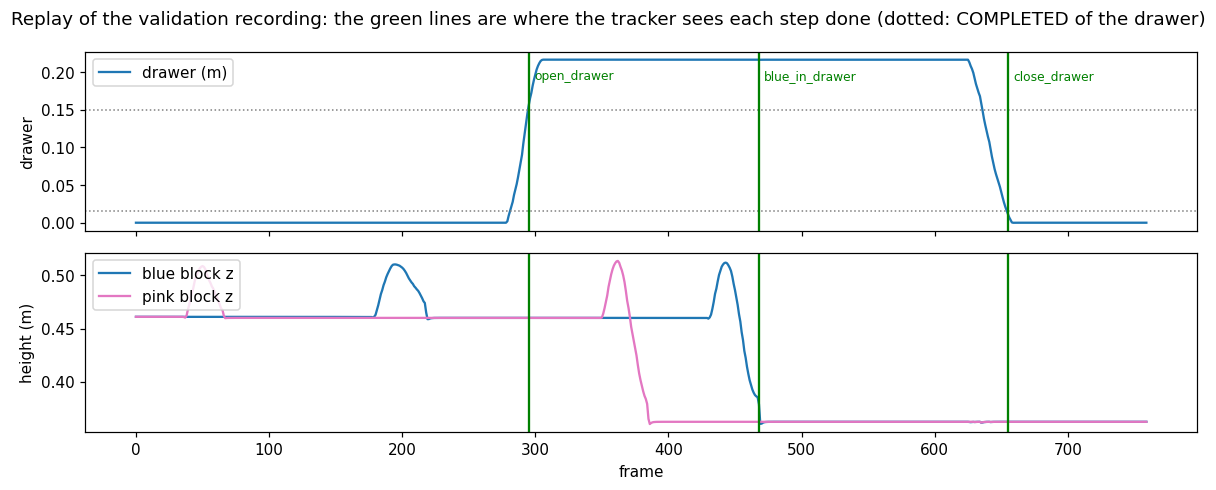

In [4]:
end = 760
t = np.arange(end)
fig, axes = plt.subplots(2, 1, figsize = (11, 4.5), sharex = True)
axes[0].plot(t, recording.states[:end, 1], label = "drawer (m)")
axes[0].axhline(0.15, color = "gray", ls = ":", lw = 1); axes[0].axhline(0.015, color = "gray", ls = ":", lw = 1)
axes[0].set_ylabel("drawer"); axes[0].legend(loc = "upper left")
axes[1].plot(t, recording.states[:end, 14], label = "blue block z", color = "tab:blue")
axes[1].plot(t, recording.states[:end, 20], label = "pink block z", color = "tab:pink")
axes[1].set_ylabel("height (m)"); axes[1].set_xlabel("frame"); axes[1].legend(loc = "upper left")
for step in summary["steps"]:
    for ax in axes:
        ax.axvline(step["completed_at"], color = "green", lw = 1.5)
    axes[0].text(step["completed_at"] + 4, 0.19, step["name"], color = "green", fontsize = 8)
fig.suptitle("Replay of the validation recording: the green lines are where the tracker sees each step done (dotted: COMPLETED of the drawer)")
fig.tight_layout()

The drawer step completes when the drawer passes 0.15. The block step completes when the blue block is in the drawer (below z = 0.40) and the gripper has let go. The pink block, which went in first, doesn't count. The close step completes when the drawer is back below 0.015 with the blue block still inside.

## 6. Goal checks for blocks

Block goals work in two ways.

**As events** (`behaviors`, `any_behaviors`, `avoid_behaviors`), measured from the start of the step:
- `red_displace`, `blue_displace`, `pink_displace`: the block moved by more than 1 cm while the robot is at it (existed before);
- `red_lift`, `blue_lift`, `pink_lift` (**new**): the block rose by more than 3 cm while the robot is at it. These also work in the single-goal `target_behaviors`.

**As states** (`where`, `blocks_moved`), checked when the step completes. The `where` language of `find_frames` is shared with the goals files of `create_guidance_conditions.py`, so the words that find condition frames also check goals:

| Spec | Meaning |
|---|---|
| `"drawer"`, `"table"`, `"cabinet"`, `"cabinet_left"`, `"cabinet_right"` | where the block is (existed) |
| `"table_left"`, `"table_center"`, `"table_right"` (**new**) | the table in thirds along x |
| `"held"`, `"lifted"` | in the closed gripper / held above where it can rest (existed) |
| `"released"` (**new**) | not in the gripper: placed and let go |
| `"resting"` (**new**) | not held and at rest height on the table, cabinet floor or drawer floor |
| `["drawer", "released"]` (**new**) | a list: all must hold |
| `{"near": [x, y, z], "radius": 0.05}` (**new**) | within a radius of a point |
| `{"near": "red", "radius": 0.08}` (**new**) | within a radius of another block |
| `{"on": "red"}` (**new**) | stacked on the red block |
| `blocks_moved: {"blue": 0.05}` (**new**, step key) | at least 5 cm from where it was at the start of the step |

How often each holds in the validation recording:

In [5]:
print("block words:", BLOCK_WORDS)
for color in ["red", "blue", "pink"]:
    counts = {str(word) : int(find_frames(recording, {"blocks" : {color : word}}).sum()) for word in ["drawer", ["drawer", "released"], "table", "table_left", "table_center", "cabinet", "held", "lifted", "resting"]}
    print(color.ljust(5), counts)
print("blue on red:", int(find_frames(recording, {"blocks" : {"blue" : {"on" : "red"}}}).sum()),
      "| blue within 8 cm of pink:", int(find_frames(recording, {"blocks" : {"blue" : {"near" : "pink", "radius" : 0.08}}}).sum()))

block words: ['drawer', 'table', 'table_left', 'table_center', 'table_right', 'cabinet', 'cabinet_left', 'cabinet_right', 'held', 'lifted', 'released', 'resting']
red   {'drawer': 0, "['drawer', 'released']": 0, 'table': 1386, 'table_left': 1386, 'table_center': 0, 'cabinet': 199, 'held': 109, 'lifted': 78, 'resting': 1566}
blue  {'drawer': 995, "['drawer', 'released']": 984, 'table': 348, 'table_left': 0, 'table_center': 347, 'cabinet': 183, 'held': 165, 'lifted': 114, 'resting': 1478}
pink  {'drawer': 852, "['drawer', 'released']": 841, 'table': 296, 'table_left': 293, 'table_center': 3, 'cabinet': 446, 'held': 111, 'lifted': 80, 'resting': 1563}
blue on red: 28 | blue within 8 cm of pink: 42


## 7. DynaGuide's side: guidance per step and the switch

`core/multigoal_guidance.py`.

**Guidance.** `MultiGoalGuidance.build` runs `calculate_classifier_guidance` once per step, with that step's conditions, `scale` and `alpha`. The object is passed to the policy as the guidance function and delegates to the current step, so the diffusion policy code is unchanged.

**Switching.** After every env step, `observe()` decides whether the current step is done. DynaGuide has to notice this *by itself*, from the camera image, without the simulator state.

### The goal switch in short

```
camera image after every env step
   │  DINO patches (256 patches × 384 numbers), the same encoder as in the guidance, no prediction
   ▼
change score: how much of the step's change does the image show?   −1 = as before the step   +1 = as in the goal conditions
   │          compared with the goal conditions and their "before" twins
   ▼
done when   score > margin (0.2)   and   the score has stopped rising for patience (10) checks
   │
   ▼
next goal step: its conditions, scale and alpha. The queued actions of the old goal are thrown away
```

- **Why not simply the distance to the goal conditions?** The guidance distance contains the whole image, and the arm is a large part of it. For the guidance that is good, it pulls the arm to the right place. For the question *is it done?* it is wrong: with the previous switch, an arm that left the drawer looked like progress towards the button, and the switch fired in 17 of 20 rollouts before the button was pressed (section 8).
- **The idea:** compare the image only along what the step *changes*. The arm isn't part of that.
- **The same rule and the same numbers for every joint goal.** Nothing is specific to the button or the drawer.

### What the change is: goal conditions and their twins

For every goal condition, `make_task.py` renders a twin: the same scene and the **same robot pose**, but the joint of the step as it was **before** the step (drawer still closed, LED still off). Everything else is identical, so the difference of the two images is exactly what the step changes.

The plot shows it for the chain drawer → button → door: a condition, its twin, and how much each patch differs, averaged over the conditions. Bright patches decide, dark patches have no say. There is no threshold and no mask drawn by hand.

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


ROBOMIMIC WARNING(
    No private macro file found!
    It is recommended to use a private macro file
    To setup, run: python /Users/pauldeufel/Desktop/TUM_local/04_WiSe26_27_Korea/3. IR/IntelligentRobotics-Team04/DynaGuide-main/robomimic/robomimic/scripts/setup_macros.py
)


Using cache found in /Users/pauldeufel/.cache/torch/hub/facebookresearch_dinov2_main
/Users/pauldeufel/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/pauldeufel/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/pauldeufel/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


/Users/pauldeufel/anaconda3/envs/ml/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


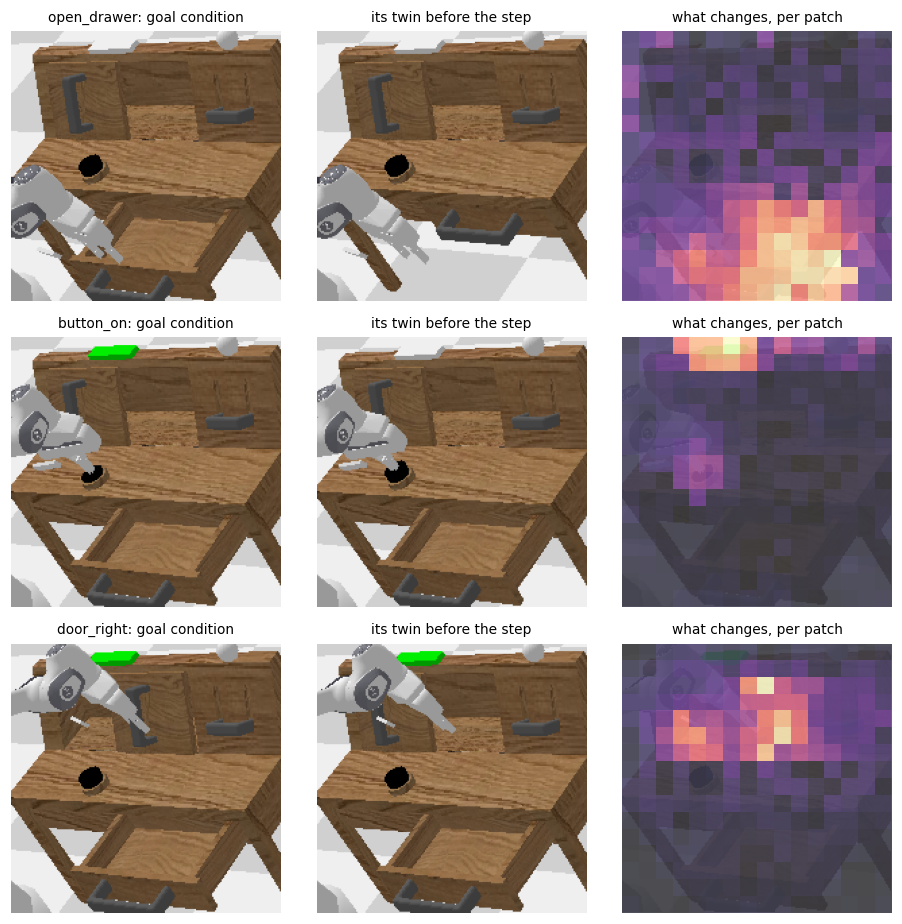

In [6]:
import h5py, torch
from core.dynamics_models import FinalStatePredictionDino
from core.multigoal_guidance import CHANGE_DEFAULTS, change_score, embed_states

TASK = "datasets/guidance_conditions/drawer_button_door"
def last_images(path):
    with h5py.File(path, "r") as file:
        return [file[f"data/demo_{i}/obs/third_person"][-1] for i in range(len(file["data"]))]

embedded = dict()
if os.path.exists(f"{TASK}/button_on_before.hdf5") and os.path.exists("dynamics_model_5900.pth"):
    model = FinalStatePredictionDino(7, 16, cameras = ["third_person"], reconstruction = True, proprio = "proprio", proprio_dim = 15)
    model.load_state_dict(torch.load("dynamics_model_5900.pth", map_location = "cpu"))
    model.eval()
    def embed(images):
        states = [{"third_person" : np.transpose(image, (2, 0, 1)).astype(np.float32), "proprio" : np.zeros(15, np.float32)} for image in images]
        return embed_states(model, states)
    pairs = {step : [last_images(f"{TASK}/{step}{end}.hdf5") for end in ["", "_before"]] for step in ["open_drawer", "button_on", "door_right"]}
    embedded = {step : [embed(images) for images in pair] for step, pair in pairs.items()}
    fig, axes = plt.subplots(3, 3, figsize = (8.5, 8.5))
    for row, (step, (goal_images, before_images)) in zip(axes, pairs.items()):
        goal, before = embedded[step]
        difference = (goal - before).reshape(len(goal), 256, 384).norm(dim = 2).mean(dim = 0).reshape(16, 16)
        for ax, image, title in zip(row, [goal_images[0], before_images[0]], [f"{step}: goal condition", "its twin before the step"]):
            ax.imshow(image)
            ax.set_title(title, fontsize = 9)
        row[2].imshow(goal_images[0], alpha = 0.35)
        row[2].imshow(difference, extent = (0, 200, 200, 0), cmap = "magma", alpha = 0.7)
        row[2].set_title("what changes, per patch", fontsize = 9)
    for ax in axes.flat:
        ax.axis("off")
    fig.tight_layout()

### The change score

With the patches $g_k$ of goal condition $k$, $b_k$ of its twin and $q$ of the current image, all flattened:

$$\text{score}(q) = \frac{\sum_k \left( \lVert q - b_k \rVert^2 - \lVert q - g_k \rVert^2 \right)}{\sum_k \lVert g_k - b_k \rVert^2}$$

- **One pair:** this is the position of $q$ on the line from $b_k$ ($-1$) to $g_k$ ($+1$). What doesn't lie along this line adds **nothing**: $\lVert q-b\rVert^2 - \lVert q-g\rVert^2 = 2\,(q - \tfrac{g+b}{2})\cdot(g-b)$, and where a patch doesn't change, $g-b$ is 0. That is why the arm drops out wherever it isn't in front of the object.
- **All pairs:** the average, weighted by how far goal and twin are apart. A pair in which the arm hides the object barely counts.
- **No unit:** the drawer moves many patches, the LED and the button only a few. Dividing by the distance of the pairs brings all goals to a similar scale, so one margin works for all.

A check on the conditions themselves: each goal condition and each twin scored with the **other** conditions of its step.

In [7]:
for step, (goal, before) in embedded.items():
    keep = lambda i: [j for j in range(len(goal)) if j != i]
    done = [float(change_score(goal[keep(i)], before[keep(i)], goal[i:i + 1])[0]) for i in range(len(goal))]
    not_done = [float(change_score(goal[keep(i)], before[keep(i)], before[i:i + 1])[0]) for i in range(len(goal))]
    print(f"{step:12s} goal conditions {min(done):5.2f} to {max(done):5.2f}    twins {min(not_done):5.2f} to {max(not_done):5.2f}")

open_drawer  goal conditions  0.41 to  0.76    twins -0.90 to -0.70
button_on    goal conditions  0.67 to  0.94    twins -1.00 to -0.75


door_right   goal conditions  0.48 to  0.62    twins -0.72 to -0.53


### When a step is done

`SwitchCriterion`, criterion `change`. After each env step, starting `min_steps` (10) steps into the goal step:

1. **The score is above `margin`** (0.2).
2. **It has stopped rising:** no new maximum, by more than `tolerance` (0.05), for `patience` (10) checks. While the drawer still moves, the score still rises. Without this, the switch comes when the joint is only halfway.
3. A score of 0 or less starts over: the change was undone or never there.

Then DynaGuide moves on: next conditions, `scale` and `alpha`; with `replan_on_switch` the queued actions of the old goal are thrown away.

- **The goal already holds at the start** (the LED is already on): the step is skipped after `patience` checks.
- **The last step** never switches, the env ends the episode.
- **The oracle** (`"mode": "oracle"`) moves on when the env sees the step done. For comparison only, section 9.

The settings, `change` overrides the general ones below it:

In [8]:
print("change:", json.dumps(CHANGE_DEFAULTS))
print(json.dumps(SWITCH_DEFAULTS, indent = 2))

change: {"criterion": "change", "margin": 0.2, "tolerance": 0.05, "patience": 10}
{
  "mode": "latent",
  "embedding": "observed",
  "criterion": "peak",
  "margin": 30.0,
  "tolerance": 5.0,
  "ratio": 1.0,
  "threshold": null,
  "patience": 5,
  "min_steps": 10,
  "check_every": 1,
  "replan_on_switch": true,
  "changed": 0.3
}


### Only the changed patches (criterion `patches`)

Same idea and same numbers as `change`, with two differences. The score of query $q$ and pair $k$ (goal $g_k$, twin $b_k$) is

$$s_k(q) = \frac{\sum_{p \in P_k} \left( \lVert q_p - b_{k,p} \rVert^2 - \lVert q_p - g_{k,p} \rVert^2 \right)}{\sum_{p \in P_k} \lVert g_{k,p} - b_{k,p} \rVert^2}, \qquad \text{score}(q) = \max_k s_k(q)$$

1. **Only the changed patches** $P_k$: those in which goal and twin differ by more than 30 % (`changed`) of the strongest patch of the pair. The rest of the 256 patches has no say.
2. **The best fitting pair counts**, not the average. For a block that is let go, one condition with the right place is enough. The average asks for all places at once.

Done when the score is above `margin` **0.5** and has stopped rising for `patience` 10 checks. −1 as before, +1 as in the goal.

**Releases.** The twin of a release step is the same image **without the block**. The guidance conditions show only 12 places, and a block 4 cm from all of them looks like none of them. So `make_task.py` renders `<step>_switch.hdf5` for the switch alone: the block at a grid of places 3 cm apart over the whole drawer floor (about 53) or table third. Places where the table or the arm hides the block are left out, such a pair would only measure noise. The guidance keeps its own conditions.

**Where it comes from.** DynaGuide's latent space is the DINOv2 patches, all 256 with the same weight in one distance. Describing a goal as a *change* is the idea of [ZeST](https://arxiv.org/abs/2204.11134) (which compares two differences by cosine), comparing patches from the same robot pose is used by [MILES](https://arxiv.org/abs/2410.19693) to detect disturbances, and stopping when nothing rises any more is related to the plateaus of [UVD](https://arxiv.org/abs/2310.08581). Keeping only the changed patches and taking the best pair is our own addition.

### Which steps use it

| Step | Criterion by default |
|---|---|
| changes a joint (`articulated/...` poses): drawer, door, switch, button | `change`. `patches` is an option (`"switch": {"criterion": "patches"}`) until the workstation run has tested it |
| lets go of a block (`release_...` poses) | `patches`, with `goal_examples` and `before_examples` from `make_task.py` |
| grips a block | `peak`, the older criterion below |
| no twins (a task made before, a config written by hand) | `peak`, without contrast conditions `relative` |

A plan's `switch_variants` can choose one criterion for the whole task, e.g. `{"criterion": "patches"}` or `{"criterion": "peak"}`.

**Why `change` isn't enough for blocks.** The average over the pairs needs a change that looks the same every time:
- **Grip:** at the moment of the grip the block hasn't moved. What changes is the gripper, and that is the arm.
- **Release:** the block can lie anywhere in the area, so the conditions don't agree on which patches change.

The `change` scores of block steps on a few D split recordings, twin = block at its old place (grip) or still in the gripper (release):

In [9]:
path = "results/goal_switch_exploration/blocks.json"
if os.path.exists(path):
    print(f"{'':24s}events    AUC   done: median   share above margin 0.2   not done: highest 2 %")
    for name, row in json.load(open(path)).items():
        print(f"{name:24s}{row['events']:6d}{row['auc']:7.2f}{row['done_median']:15.2f}{row['done_share_above_margin']:25.2f}{row['not_done_high']:24.2f}")

                        events    AUC   done: median   share above margin 0.2   not done: highest 2 %
grip                        10   0.86          -0.20                     0.21                   -0.03
release on the table         8   0.77          -0.05                     0.25                    0.18
release in the drawer       14   0.98          -0.02                     0.20                   -0.13


### The older criteria

Kept for grip steps and for comparison, chosen with e.g. `"switch": {"criterion": "peak"}`. They use the whole image: `d_goal` is the soft-min distance to the step's goal conditions, `d_contrast` to **contrast conditions** that show the state before the goal (by default the goal conditions of the step before; for the first step `contrast_examples`).

- **`peak`:** the score `c = d_contrast − d_goal` rose above `margin` (30) and made no new maximum (by more than `tolerance` 5) for `patience` (5) checks, after it was ≤ 0 once. The arm is in both distances, but it only cancels out if it stands as in the contrast conditions. When it leaves the place of the step before, `c` rises without anything being done.
- **`contrast`:** `c > margin` for `patience` checks. **`relative`:** `d_goal` below `ratio` × the spread of the goal conditions. **`threshold`:** `d_goal` below a number.
- **`embedding`: `predicted`** compares the dynamics model's prediction instead of the DINO patches of the image. It was clearly worse (section 8).

## 8. Testing the switch

Three tests of both criteria, all with `dynaguide_scripts/test_goal_switch.py`. The truth is always the simulator state (the joint, or where the block is), which the switch never sees.

| Test | What | Where |
|---|---|---|
| `recordings` | the switch over recorded demos and rollouts, the conditions made in the scene each one starts from | below; more of it in the workstation scripts |
| `live` | what the switch did in rollouts in which it really steered | the workstation scripts |
| `replay` | the switch over every frame of those rollouts, also for steps DynaGuide wasn't at, to find false switches | the workstation scripts |

**What is counted**, per episode and step:

| | |
|---|---|
| correct | switched while the joint is past `COMPLETED`, as the env counts it; with the delay in env steps |
| on the way | switched with the joint between start and `COMPLETED`; the joint values are listed |
| **false** | switched with the joint still at the start |
| **missed** | past `COMPLETED` for 40 steps, not switched |
| too short | reached, but the recording ends before the switch could react |
| quiet | not reached, not switched: as it should be |
| already | reached before the step began, no test |

### The change criterion on recordings

- **D split demos:** 56 recorded behaviors, 7 of each. Each is rendered in the simulator and scored with conditions in its own start scene, without the pose that comes from the same demo. Each also with two other goals, which must stay quiet.
- **Single-goal rollouts:** guided and base policy rollouts of the earlier experiments, with their goal and another one.
- **Chain rollouts:** rollouts of drawer → button → door that ran with the previous switch and the oracle. Every step's switch runs over the whole rollout.

Every 3rd to 10th frame. The settings were chosen on these recordings, so this isn't an independent test. That is the one on the workstation.

In [10]:
from test_goal_switch import OUTCOMES, Scores, evaluate, joint_side
SWITCH_SETTINGS = {**SWITCH_DEFAULTS, **CHANGE_DEFAULTS}
scores_file = "results/goal_switch_exploration/scores.npz"
if os.path.exists(scores_file):
    scores = Scores.load(scores_file)
    table = evaluate(scores, SWITCH_SETTINGS)
    groups = sorted({group for group, _ in table.rows})
    print(f"{'':40s}" + "".join(f"{name:>11s}" for name in OUTCOMES))
    for group in groups + [None]:
        print(f"{group or 'all':40s}" + "".join(f"{n:11d}" for n in table.totals(group).values()))
    delays = [delay for row in table.rows.values() for delay in row["delays"]]
    print(f"\ndelay after the env sees it: mean {np.mean(delays):.1f}, max {max(delays)} steps")
    print("on the way:", {behavior : row["joint_on_the_way"] for (_, behavior), row in table.rows.items() if row["joint_on_the_way"]})

pybullet build time: Nov  7 2026 21:49:32


                                            correct on the way      false     missed  too short      quiet    already
D split demos (another goal)                      0          0          0          0          0        111          0
D split demos (its goal)                         52          4          0          0          0          0          0
chain rollouts                                   33          0          0          0          0         30          0
single-goal rollouts (another goal)               3          0          0          0          0         40          0
single-goal rollouts (its goal)                   0          0          0          0          6         36          0
all                                              88          4          0          0          6        217          0

delay after the env sees it: mean 15.2, max 40 steps
on the way: {'drawer_close': [0.019], 'door_left': [0.251, 0.258], 'switch_on': [0.079]}


/Users/pauldeufel/Desktop/TUM_local/04_WiSe26_27_Korea/3. IR/IntelligentRobotics-Team04/DynaGuide-main/calvin/calvin_env/calvin_env/envs/play_table_env.py:386: UserWarning: 
The version_base parameter is not specified.
Please specify a compatability version level, or None.
Will assume defaults for version 1.1
  @hydra.main(config_path="../../conf", config_name="config_data_collection")


### One margin for all goals

Left: the score of every frame, at the start and where the goal is reached. Right: what the switch does for other margins and patience values. Without waiting for the score to settle (patience 3), it often switches while the joint still moves.

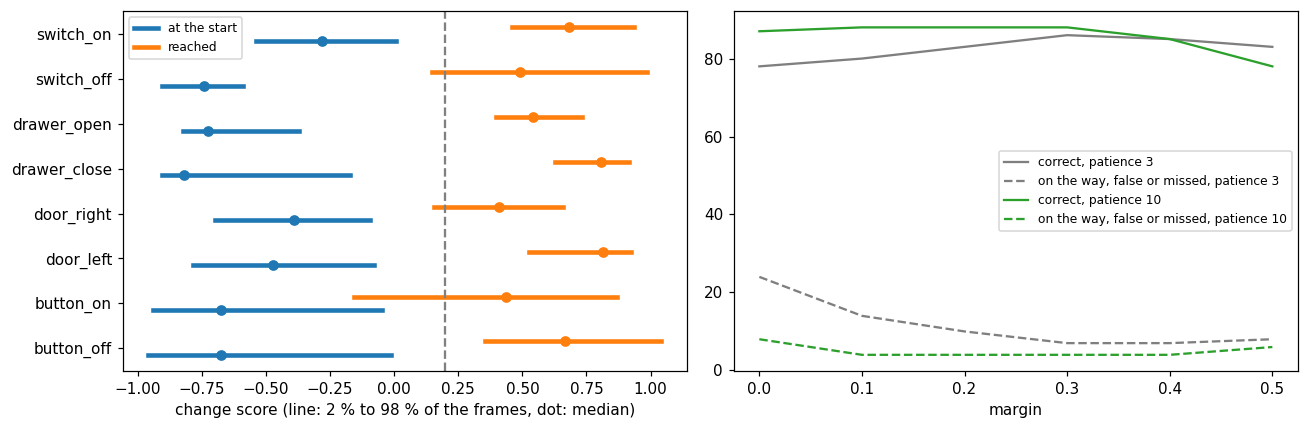

In [11]:
if os.path.exists(scores_file):
    behaviors = sorted({entry["behavior"] for entry in scores.entries})
    fig, (left, right) = plt.subplots(1, 2, figsize = (12, 4))
    for row, behavior in enumerate(behaviors):
        found = [e for e in scores.entries if e["behavior"] == behavior]
        score, side = np.concatenate([e["score"] for e in found]), np.concatenate([joint_side(behavior, e["joint"]) for e in found])
        for value, color, offset, label in [(0, "tab:blue", -0.15, "at the start"), (1, "tab:orange", 0.15, "reached")]:
            s = score[side == value]
            left.plot(np.quantile(s, [0.02, 0.98]), [row + offset] * 2, color = color, lw = 3, label = label if row == 0 else None)
            left.plot(np.median(s), row + offset, "o", color = color)
    left.axvline(CHANGE_DEFAULTS["margin"], color = "gray", ls = "--")
    left.set_yticks(range(len(behaviors)), behaviors)
    left.set_xlabel("change score (line: 2 % to 98 % of the frames, dot: median)")
    left.legend(fontsize = 8, loc = "upper left")
    margins = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
    for patience, color in [(3, "tab:gray"), (10, "tab:green")]:
        totals = [evaluate(scores, {**SWITCH_SETTINGS, "margin" : m, "patience" : patience}).totals() for m in margins]
        right.plot(margins, [t["correct"] for t in totals], color = color, label = f"correct, patience {patience}")
        right.plot(margins, [t["on the way"] + t["false"] + t["missed"] for t in totals], color = color, ls = "--", label = f"on the way, false or missed, patience {patience}")
    right.set_xlabel("margin")
    right.legend(fontsize = 8)
    fig.tight_layout()

- **The plateau is wide:** margins 0.1 to 0.3 give the same result with patience 10. The value isn't tuned to a behavior.
- **The button is the tightest case** for single frames: when the arm hides the LED or the button, a frame can score low although the light is on. The switch then waits until it is visible again.

### The patches criterion offline

Offline, one process on the Mac, the margin 0.5 fixed beforehand for the last two rows:

| Test | Result |
|---|---|
| Joints: 24 D split recordings, 3 per behavior | 22 correct, 2 just short of the env's limit, 0 false (same as `change`). Margins 0.5 to 0.65 give the same, at 0.7 four are missed |
| Another goal running over the same recordings | 24 of 24 quiet |
| Button step of 6 old chain rollouts (4 pressed, 2 not) | 4 of 4 correct, 2 of 2 quiet |
| Release, D split, 10 per place, conditions at their places | drawer 6/10, table 7/10, one false each. With the block's true place: 10/10 and 10/10 |
| **Release into the drawer, robot rollouts** (`blue_drawer_end`, 16 that ended with the block in the drawer, the arm moved out of the way) | 2 of 16 above 0.5 with the 12 conditions, **14 of 16 with the grid** |
| **False switches of the release step**, 25 whole rollouts that never put the block in the drawer (24 drawn at random, one picked because it was false) | 3 of 25 at margin 0.5 (2 of the 24 random ones, 8 %), 0 of 25 at 0.6 and 0.7 |
| Grip (D split, 10) | 2 to 3 of 10, no working criterion |

- **What the false switches show:** in the first one, the gripper stood in the drawer and the robot had closed the drawer. The twins show an open drawer, so the score compares a scene that isn't there any more.
- **Margin 0.6** would have had fewer false switches (12 of the 16 stay above it). It isn't set, because it would be chosen on this test. The release replay on the workstation decides.
- **What isn't tested:** a switch after a release while the robot really steers. The rollouts above end at the release.
- **ZeST's formula** (cosine of two differences, on the same patches) was tried as well. No single margin worked for joints and blocks: at 0.07 it gave 4 false switches of 24 joints, at 0.15 at most 2 of 10 per block step.

### On the workstation

`dynaguide_scripts\run_goal_switch.bat` (section 1.7) runs everything, about 17 hours; with `short` behind it without the previous switch, about 12 hours. It continues where it stopped.

| Chain | Steps |
|---|---|
| `drawer_button_door` | open the drawer, button on, door right |
| `door_drawer_switch` | door left, close the drawer, switch on |
| `button_switch_drawer` | button off, switch off, open the drawer |
| `door_switch_button` | door right, switch on, button off |

Each of the eight joint behaviors is once a step the switch has to end. 20 rollouts per chain with the new switch (`change`), the oracle and the switch from before (`previous`), from the same start scenes.

How to read it:
- **`change` against `oracle`, reach rates of the steps:** what the switch costs. Equal means the switch isn't the limit, what is missing is the guidance.
- **`false` and `missed` in `switch_live.json`:** the errors of the switch itself. `on the way` close to `COMPLETED` is nearly done for the robot, but the env doesn't count the step.
- **`switch_replay.json`:** the same over all frames, with other margins and patience values. If another value is clearly better there, that is the one to change.

**`run_goal_switch_patches.bat`** tests the `patches` criterion, about 5 hours of rollouts and 1 to 2.5 hours of replay.

| Part | What | Why |
|---|---|---|
| 4 × 20 rollouts | the same four chains, start scenes and guidance settings, only the switch is `patches` (margin 0.5) | every joint behavior is once a step the switch has to end, and the runs compare directly with `change` and `oracle` of the first script. No new oracle runs needed |
| Replay of both criteria | every frame of these rollouts, also of `results/goal_switch` when it is on the machine | false and missed switches of both criteria on the **same** frames, with other margins |
| Release replay | the 280 rollouts of `blue_drawer_end` and `blue_drawer_end_1.1`, when they are on the machine | the only recorded block rollouts of the robot: 16 end with the block in the drawer, 264 don't. It shows the false switches. Those rollouts end when the block rests, so correct switches can't show up there |

**Not in it:** live block chains. The robot brings the block into the drawer in 0 to 25 % of the rollouts and never yet as a step before others, so a switch after it would almost never be tested. A grip has no working criterion yet.

Why the margin isn't chosen from this run: 0.5 was fixed before it, so the run is an independent test of it. The sweep shows whether another value would be better, which then needs a new test.

In [12]:
FILES = ["goal_switch/switch_live.json", "goal_switch/switch_replay.json", "goal_switch_patches/switch_live.json",
         "goal_switch_patches/switch_replay.json", "goal_switch_patches/switch_replay_patches.json",
         "goal_switch_patches_release/right/switch_replay_patches.json", "goal_switch_patches_release/center/switch_replay_patches.json"]
for name in FILES:
    file = f"results/{name}"
    if not os.path.exists(file):
        print(f"{file}: not there yet")
        continue
    result = json.load(open(file))
    print(f"\n{file}\n{'':44s}" + "".join(f"{n:>11s}" for n in OUTCOMES))
    for row_name, row in result["outcomes"].items():
        print(f"{row_name:44s}" + "".join(f"{row[n]:11d}" for n in OUTCOMES))
    for run, row in result.get("runs", {}).items():
        print(f"{run:44s} success {row['success']}/{row['episodes']}, reached {row['step_reach_rate']}")

results/goal_switch/switch_live.json: not there yet
results/goal_switch/switch_replay.json: not there yet
results/goal_switch_patches/switch_live.json: not there yet
results/goal_switch_patches/switch_replay.json: not there yet
results/goal_switch_patches/switch_replay_patches.json: not there yet
results/goal_switch_patches_release/right/switch_replay_patches.json: not there yet
results/goal_switch_patches_release/center/switch_replay_patches.json: not there yet


### What the previous switch did

The rollouts of `drawer_button_door` from before this switch (`latent` = `peak`). In the button step it moved on without the light being on in almost every rollout.

In [13]:
from types import SimpleNamespace
from test_goal_switch import live
if os.path.isdir("results/drawer_button_door"):
    live(SimpleNamespace(results = ["results/drawer_button_door"], output = "results/goal_switch_exploration/previous"))


Every switch of every rollout

                                                correct on the way      false     missed  too short      quiet    already   delay mean / max
three_steps/base_policy drawer_open                  10          0          0          0          0         10          0      0.0 / 0
three_steps/base_policy button_on                     1          0          0          0          0          5          4      0.0 / 0
three_steps/latent drawer_open                       19          1          0          0          0          0          0     12.6 / 16
      on the way at [0.104], reached is 0.15
three_steps/latent button_on                          0          0         17          2          0          0          1   -
      demo_0 (missed), demo_1 (false), demo_2 (false), demo_3 (false), demo_4 (false), demo_5 (false), demo_6 (false), demo_7 (false), demo_8 (false), demo_9 (false), demo_10 (false), demo_11 (false), demo_12 (false), demo_14 (false), demo_15 (false)

### Calibrating the older criteria

`dynaguide_scripts/calibrate_goal_switching.py` measures the switch on recordings that the conditions don't come from. It embeds every frame and every condition and saves the raw distances (`distances.npz`), then computes all criteria from those. The criteria can be changed without embedding again (`--analyze_only`), and the analysis below runs from the saved file.

**Labels.** Each frame is *reached* for a behavior if the joint is at `COMPLETED` of that behavior, *not reached* if it is still on the start side (`ARTICULATED`), and left out in between. The contrast of a behavior is its opposite (drawer_close for drawer_open).

**Two setups:**

| | Conditions | Evaluation frames | Command |
|---|---|---|---|
| **sim** (the one that matters) | the recombined conditions the experiments use (`recombined_debug`), **without** those made from the validation recording | the validation recording **rendered in the simulator** (`render_recording_in_sim.py`), the image domain of the rollouts | section 1.9 |
| dataset | cut from the training recording (2 to 3 per behavior) | the original validation recording (EGL images) | section 1.9 |

The validation recording has 1675 frames with 2 drawer openings, 1 closing, 1 door left, 1 door right, 2 switch on and 1 switch off. That is few behaviors, but many frames (≈800 reached and ≈800 not reached per drawer/switch behavior).

In [14]:
from calibrate_goal_switching import OPPOSITE, JOINT_OF, analyze, episodes_of, frame_labels, scores_of, run_criterion

def load(folder):
    paths = [os.path.join(root, folder, "distances.npz") for root in ["results", "results/diagnosis_runs"]] # moved there
    return next((dict(np.load(path)) for path in paths if os.path.exists(path)), None)

sim = load("multigoal_calibration_sim")
dataset = load("multigoal_calibration")
results = {name : analyze(data) for name, data in [("sim", sim), ("dataset", dataset)] if data is not None}

rows = []
for setup, result in results.items():
    for behavior, entry in result.items():
        for kind in ["observed", "predicted"]:
            auc = entry[kind]["auc"]
            rows.append(f"| {setup} | {behavior} | {entry['conditions']} | {kind} | {auc['threshold']:.3f} | {auc['contrast']:.3f} |")
from IPython.display import Markdown
Markdown("**Frame-level AUC: reached vs. not reached** (1 = perfect, 0.5 = chance)\n\n| setup | behavior | conditions | embedding | d_goal alone | contrast |\n|---|---|---|---|---|---|\n" + "\n".join(rows))

**Frame-level AUC: reached vs. not reached** (1 = perfect, 0.5 = chance)

| setup | behavior | conditions | embedding | d_goal alone | contrast |
|---|---|---|---|---|---|
| sim | drawer_open | 16 | observed | 0.927 | 1.000 |
| sim | drawer_open | 16 | predicted | 0.786 | 0.863 |
| sim | drawer_close | 16 | observed | 0.881 | 1.000 |
| sim | drawer_close | 16 | predicted | 0.859 | 0.869 |
| sim | door_left | 24 | observed | 0.266 | 0.811 |
| sim | door_left | 24 | predicted | 0.310 | 0.602 |
| sim | door_right | 16 | observed | 0.890 | 0.806 |
| sim | door_right | 16 | predicted | 0.801 | 0.604 |
| sim | switch_on | 16 | observed | 0.545 | 1.000 |
| sim | switch_on | 16 | predicted | 0.522 | 0.925 |
| sim | switch_off | 16 | observed | 0.627 | 1.000 |
| sim | switch_off | 16 | predicted | 0.593 | 0.926 |
| dataset | drawer_open | 2 | observed | 0.837 | 0.997 |
| dataset | drawer_open | 2 | predicted | 0.765 | 0.843 |
| dataset | drawer_close | 2 | observed | 0.731 | 0.997 |
| dataset | drawer_close | 2 | predicted | 0.725 | 0.848 |
| dataset | door_left | 3 | observed | 0.495 | 0.511 |
| dataset | door_left | 3 | predicted | 0.503 | 0.456 |
| dataset | door_right | 2 | observed | 0.505 | 0.503 |
| dataset | door_right | 2 | predicted | 0.464 | 0.462 |
| dataset | switch_on | 2 | observed | 0.641 | 0.710 |
| dataset | switch_on | 2 | predicted | 0.539 | 0.704 |
| dataset | switch_off | 2 | observed | 0.558 | 0.714 |
| dataset | switch_off | 2 | predicted | 0.612 | 0.708 |

**What the AUCs say:**

- **The contrast beats the distance to the goal alone**, by far. With `d_goal` alone (your initial guess, an absolute or relative threshold on the distance to the goal conditions), the switch and door are close to chance or even inverted. The robot pose and the blocks dominate `d_goal`. With the contrast, drawer and switch are separated perfectly in the sim setup, and the door reaches about 0.81.
- **Observed beats predicted.** The prediction of the dynamics model adds its own error. With the predicted embedding, the contrast drops to 0.6 to 0.93.
- **The sim setup is the relevant one** and is better than the dataset setup. It has 16 to 24 recombined conditions instead of 2 to 3, and they differ only in what matters. The images match the rollouts' renderer.

**Which level of the score means "done".** A good AUC isn't enough. The switch must not come **before** the env sees the step done, otherwise the robot might e.g. close a half-opened drawer, and the env never counts the opening. The traces show why a fixed level is hard and the peak works:

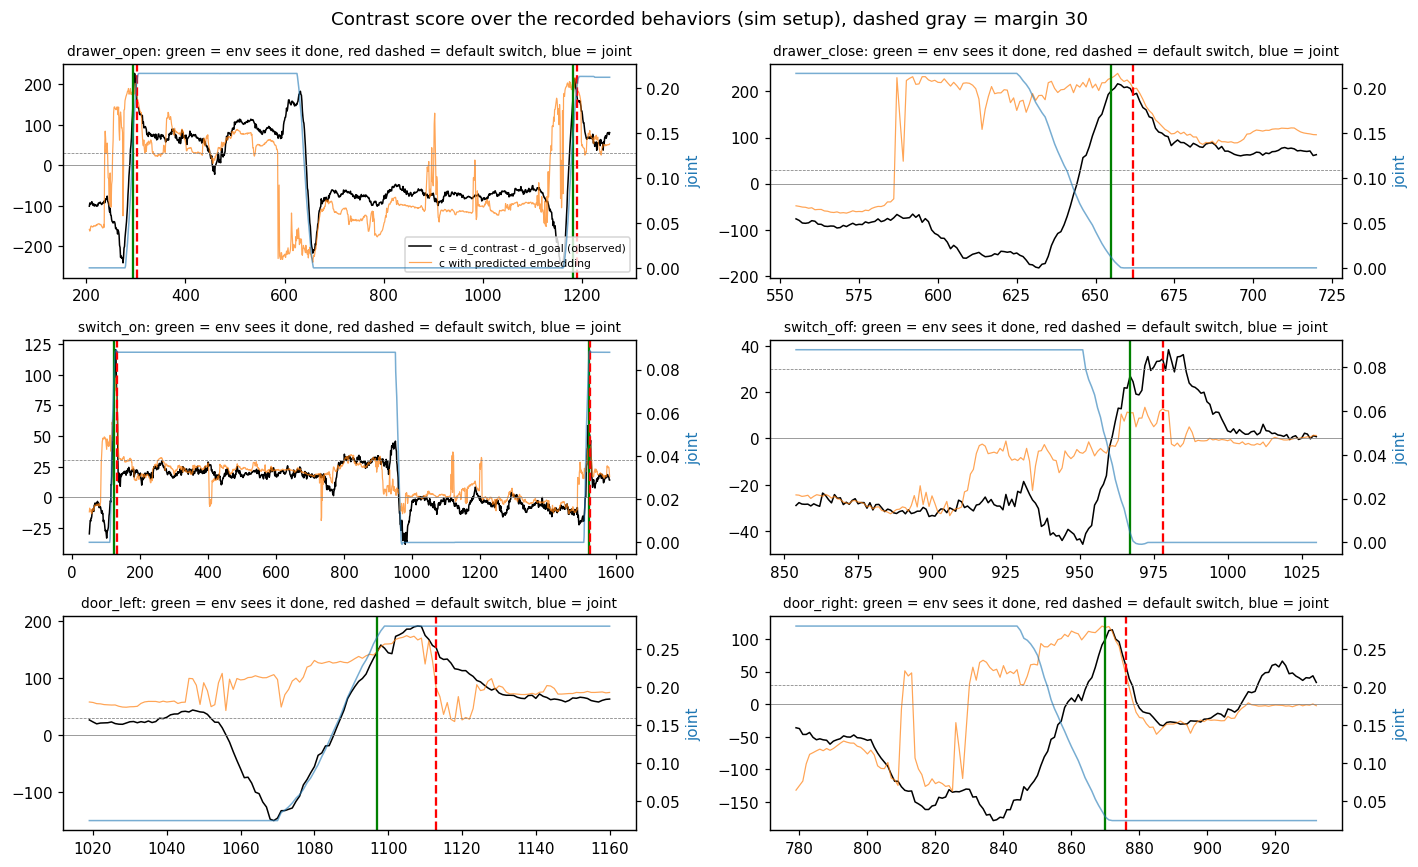

In [15]:
def trace_plot(data, behavior, ax, title):
    d_goal, d_contrast, spread = scores_of(data, "observed", behavior, 30)
    c = d_contrast - d_goal
    joint = data["states"][:, JOINT_OF[behavior][0]]
    episodes = episodes_of(data, behavior)
    window = np.arange(max(episodes[0][0][0] - 20, 0), episodes[-1][0][-1])
    ax.plot(window, c[window], color = "black", lw = 1, label = "c = d_contrast - d_goal (observed)")
    d_goal_p, d_contrast_p, _ = scores_of(data, "predicted", behavior, 30)
    ax.plot(window, (d_contrast_p - d_goal_p)[window], color = "tab:orange", lw = 0.8, alpha = 0.7, label = "c with predicted embedding")
    ax.axhline(0, color = "gray", lw = 0.5)
    ax.axhline(SWITCH_DEFAULTS["margin"], color = "gray", lw = 0.5, ls = "--")
    twin = ax.twinx()
    twin.plot(window, joint[window], color = "tab:blue", lw = 1, alpha = 0.6)
    twin.set_ylabel("joint", color = "tab:blue")
    for frames, reached in episodes:
        ax.axvline(reached, color = "green", lw = 1.5)
        switch = run_criterion(SWITCH_DEFAULTS, d_goal, d_contrast, frames, spread)
        if switch is not None:
            ax.axvline(switch, color = "red", lw = 1.5, ls = "--")
    ax.set_title(title, fontsize = 9)

if sim is not None:
    fig, axes = plt.subplots(3, 2, figsize = (13, 8))
    for ax, behavior in zip(axes.flat, ["drawer_open", "drawer_close", "switch_on", "switch_off", "door_left", "door_right"]):
        trace_plot(sim, behavior, ax, f"{behavior}: green = env sees it done, red dashed = default switch, blue = joint")
    axes[0, 0].legend(fontsize = 7, loc = "lower right")
    fig.suptitle("Contrast score over the recorded behaviors (sim setup), dashed gray = margin 30")
    fig.tight_layout()

What the traces show:

- `c` crosses 0 about **halfway** through the motion (drawer at ≈0.07 of 0.15). A switch at "looks more like the goal than the contrast" would come too early.
- The level `c` reaches at the end differs a lot: ≈200 for the drawer, ≈100 for the door, ≈40 to 120 for the switch. One fixed margin doesn't fit all behaviors. I tried two normalizations, neither worked: (a) dividing by the distance between the goal and contrast condition sets, which also contains the robot poses that cancel per frame, so the progress never got above ≈0.3; (b) anchors from leave-one-out scores of the conditions, which are distorted because the recombined sets contain the same robot pose once per joint combination.
- `c` **peaks within a few frames of the env's completion**, for every behavior: the conditions show the end of a behavior, hand at the handle. After that the robot moves away and `c` drops, but stays positive.

So the default criterion detects the peak. The sweep below runs the exact `SwitchCriterion` of the rollouts over the recorded behaviors:

In [16]:
if sim is not None:
    behaviors = list(OPPOSITE)
    sweep = results["sim"][behaviors[0]]["observed"]["sweep"]
    lines = ["| margin | patience | " + " | ".join(behaviors) + " | false alarms |", "|---|---|" + "---|" * len(behaviors) + "---|"]
    for index, row in enumerate(sweep):
        cells, alarms, switches = [], 0, 0
        for behavior in behaviors:
            entry = results["sim"][behavior]["observed"]["sweep"][index]
            cells.append(" ".join("**early**" if o == "early" else "miss" if o == "missed" else f"+{o}" for o in entry["outcomes"]))
            alarms += entry["false_alarms_whole_recording"]; switches += entry["switches_whole_recording"]
        mark = " ← default" if (row["margin"], row["patience"]) == (SWITCH_DEFAULTS["margin"], SWITCH_DEFAULTS["patience"]) else ""
        lines.append(f"| {row['margin']} | {row['patience']}{mark} | " + " | ".join(cells) + f" | {alarms} / {switches} |")
    display(Markdown("**Peak criterion (observed, sim setup) on each recorded behavior**: `+n` = n frames after the env saw it done, "
                     "**early** = before, miss = never. False alarms: running over the whole recording (restarting after each switch), "
                     "switches at frames where the goal isn't reached / all switches, summed over the 6 behaviors.\n\n" + "\n".join(lines)))

**Peak criterion (observed, sim setup) on each recorded behavior**: `+n` = n frames after the env saw it done, **early** = before, miss = never. False alarms: running over the whole recording (restarting after each switch), switches at frames where the goal isn't reached / all switches, summed over the 6 behaviors.

| margin | patience | drawer_open | drawer_close | door_left | door_right | switch_on | switch_off | false alarms |
|---|---|---|---|---|---|---|---|---|
| 0 | 3 | +5 +5 | +5 | +4 | +4 | +5 +1 | +3 | 18 / 45 |
| 0 | 5 | +7 +7 | +7 | +16 | +6 | +7 +3 | +5 | 15 / 42 |
| 0 | 8 | +10 +10 | +10 | +19 | +9 | +10 +6 | +14 | 11 / 36 |
| 10 | 3 | +5 +5 | +5 | +4 | +4 | +5 +1 | +3 | 12 / 37 |
| 10 | 5 | +7 +7 | +7 | +16 | +6 | +7 +3 | +5 | 10 / 35 |
| 10 | 8 | +10 +10 | +10 | +19 | +60 | +10 +6 | +14 | 8 / 32 |
| 20 | 3 | +5 +5 | +5 | +4 | +4 | +5 +1 | +4 | 7 / 29 |
| 20 | 5 | +7 +7 | +7 | +16 | +6 | +7 +3 | +5 | 7 / 29 |
| 20 | 8 | +10 +10 | +10 | +19 | +60 | +10 +6 | +14 | 6 / 26 |
| 30 | 3 | +5 +5 | +5 | +4 | +4 | +5 +1 | +9 | 7 / 28 |
| 30 | 5 ← default | +7 +7 | +7 | +16 | +6 | +7 +3 | +11 | 5 / 26 |
| 30 | 8 | +10 +10 | +10 | +19 | +60 | miss +6 | +14 | 4 / 21 |
| 40 | 3 | +5 +5 | +5 | +4 | +4 | +5 +1 | miss | 3 / 21 |
| 40 | 5 | +7 +7 | +7 | +16 | +6 | +7 +3 | miss | 1 / 19 |
| 40 | 8 | +10 +10 | +10 | +19 | +60 | miss +6 | miss | 1 / 17 |
| 60 | 3 | +5 +5 | +5 | +4 | +4 | +5 miss | miss | 1 / 15 |
| 60 | 5 | +7 +7 | +7 | +16 | miss | +7 miss | miss | 1 / 14 |
| 60 | 8 | +10 +10 | +10 | +19 | miss | miss miss | miss | 1 / 13 |

In [17]:
if sim is not None:
    lines = ["| behavior | embedding | switch on the recorded behaviors | joint at switch | COMPLETED | false alarms |", "|---|---|---|---|---|---|"]
    from core.calvin_behaviors import COMPLETED
    for behavior, entry in results["sim"].items():
        for kind in ["observed", "predicted"]:
            d = entry[kind]["default_switch"]
            lines.append(f"| {behavior} | {kind} | {d['outcomes']} | {d['joint_at_switch']} | {COMPLETED.get(behavior)} | {d['false_alarms_whole_recording']} / {d['switches_whole_recording']} |")
    display(Markdown("**The default switch** (peak, margin 30, patience 5, tolerance 5)\n\n" + "\n".join(lines)))

**The default switch** (peak, margin 30, patience 5, tolerance 5)

| behavior | embedding | switch on the recorded behaviors | joint at switch | COMPLETED | false alarms |
|---|---|---|---|---|---|
| drawer_open | observed | [7, 7] | [0.2084, 0.2023] | 0.15 | 0 / 5 |
| drawer_open | predicted | ['early', 'early'] | [0.0, 0.1317] | 0.15 | 4 / 9 |
| drawer_close | observed | [7] | [-0.0] | 0.015 | 0 / 1 |
| drawer_close | predicted | ['early'] | [0.2166] | 0.015 | 1 / 4 |
| door_left | observed | [16] | [0.28] | 0.26 | 2 / 12 |
| door_left | predicted | ['missed'] | [None] | 0.26 | 2 / 11 |
| door_right | observed | [6] | [0.0249] | 0.035 | 3 / 5 |
| door_right | predicted | ['early'] | [0.28] | 0.035 | 1 / 1 |
| switch_on | observed | [7, 3] | [0.0886, 0.0883] | 0.08 | 0 / 2 |
| switch_on | predicted | ['early', 3] | [0.0, 0.0883] | 0.08 | 1 / 3 |
| switch_off | observed | [11] | [-0.0001] | 0.008 | 0 / 1 |
| switch_off | predicted | ['missed'] | [None] | 0.008 | 0 / 0 |

**Result.** With the observed embedding and the default settings, the switch comes **after** the env's completion on all 8 recorded behaviors (drawer and switch 3 to 11 frames later, door 6 and 16). Over the whole recording, it has no false alarm for drawer and switch. The door has some (2 of 12, 3 of 5), consistent with its lower AUC: the sliding door changes the image less than the drawer, and its conditions vary more. The predicted embedding switches too early in most cases.

In the dataset setup, with only 2 to 3 conditions cut from the training recording, the drawer still works (switch 6 and 7 frames after the env), but switch and door mostly miss. **Enough conditions that differ only in what matters (the recombined sets) are what make the switch work.**

**The margin depends on the behavior.** The margin is the level the peak must exceed. Here it is per behavior, up to where the switch starts to miss:

In [18]:
if sim is not None:
    margins = [30, 60, 100, 120, 150, 180]
    by_margin = analyze(sim, sweep = {"margin" : margins})
    lines = ["| behavior | " + " | ".join(f"margin {m}" for m in margins) + " |", "|---|" + "---|" * len(margins)]
    for behavior, entry in by_margin.items():
        lines.append(f"| {behavior} | " + " | ".join(
            " ".join("**early**" if o == "early" else "miss" if o == "missed" else f"+{o}" for o in row["outcomes"])
            + f" (FA {row['false_alarms_whole_recording']}/{row['switches_whole_recording']})" for row in entry["observed"]["sweep"]) + " |")
    display(Markdown("Default switch with other margins (observed, sim setup). FA = false alarms / switches over the whole recording.\n\n" + "\n".join(lines)))

Default switch with other margins (observed, sim setup). FA = false alarms / switches over the whole recording.

| behavior | margin 30 | margin 60 | margin 100 | margin 120 | margin 150 | margin 180 |
|---|---|---|---|---|---|---|
| drawer_open | +7 +7 (FA 0/5) | +7 +7 (FA 0/5) | +7 +7 (FA 0/3) | +7 +7 (FA 0/3) | +7 +7 (FA 0/3) | miss miss (FA 0/0) |
| drawer_close | +7 (FA 0/1) | +7 (FA 0/1) | +7 (FA 0/1) | +7 (FA 0/1) | +7 (FA 0/1) | +7 (FA 0/1) |
| door_left | +16 (FA 2/12) | +16 (FA 0/5) | +16 (FA 0/4) | +16 (FA 0/4) | +16 (FA 0/2) | miss (FA 0/0) |
| door_right | +6 (FA 3/5) | miss (FA 1/2) | miss (FA 1/1) | miss (FA 1/1) | miss (FA 0/0) | miss (FA 0/0) |
| switch_on | +7 +3 (FA 0/2) | +7 miss (FA 0/1) | miss miss (FA 0/0) | miss miss (FA 0/0) | miss miss (FA 0/0) | miss miss (FA 0/0) |
| switch_off | +11 (FA 0/1) | miss (FA 0/0) | miss (FA 0/0) | miss (FA 0/0) | miss (FA 0/0) | miss (FA 0/0) |

So the default margin 30 is the one value that works for all behaviors. For the drawer alone, up to 150 would work on these recordings. Section 11 tests that in rollouts: it doesn't help, and the default stays 30.

**Caveats.** These are 8 recorded behaviors of one human demonstrator, not rollouts. Under guidance, the robot might hover at the goal instead of moving away; then `c` plateaus instead of dropping, which the criterion also catches (no new maximum). The rollouts in section 11 are the first check under guidance. The block steps (block in drawer) couldn't be calibrated this way: the debug set has too few placements to keep conditions and evaluation apart.

## 9. The oracle switch (ablation)

With `"switch": {"mode": "oracle"}`, DynaGuide moves on exactly when the `SequentialGoalTracker` sees the step done. It uses the simulator state, which a real robot doesn't have, so it is only for comparison:

- **oracle succeeds, latent fails** → the switch is the problem (too early, too late, never);
- **both fail** → the guidance of a step is the problem (conditions, scale, alpha), a better switch won't help;
- **oracle success rate** = the upper bound for this guidance with a perfect switch.

In a plan, both run from the same start scenes as `switch_variants` (section 1.4). The latent runs also log when the env saw each step done, so `Switching` in the results counts too-early and missed switches directly (section 1.6).

## 10. Base sets and tasks: how the conditions are made

**Why not one big set of conditions.** The guidance maximizes `log Σᵢ exp(−dᵢ/α)` over all conditions. Its gradient pulls toward every condition, weighted by `softmax(−dᵢ/α)`:
- With distances around 500–600 and α = 30–40, the nearest group of conditions dominates. One 100 units further away gets about 4 % of the weight.
- "Nearest" is measured from where the planned action chunk ends up, in the whole image, so the robot pose counts a lot.
- A group of N conditions pulls like one condition α·ln N closer.
- Different goals in one set mean "any of them": the robot goes to the nearest, reaches it and stays.

Covering every scene is impossible once blocks are involved. So there are two layers (the commands are in sections 1.1 and 1.3): **base sets** with diverse robot poses in every combination of the joints, and **tasks** that take from them what one experiment needs, in exactly the scene of its reset.

### Layer 1: base sets in `datasets/robot_poses/`

```
articulated/<behavior>/<scene>.hdf5          drawer_open, drawer_close, door_left, door_right, switch_on/off, button_on/off at their goal,
                                              no blocks, every combination of the other joints (recombine_conditions.py --hide_blocks)
blocks/<kind>/<action>_<side>/<scene>.hdf5   gripping and letting go of a block, with the blue block only, every combination of the
                                              joints (extract_block_poses.py)
blocks/poses/<kind>.hdf5                     the block poses as found, in their own scene and color
```

`<scene>` is like `drawer_open__door_left__switch_off__green_light_off`. The block sets:

| set | poses | scenes |
|---|---|---|
| `grip_table/grip_left`, `grip_center`, `grip_right` | 24, 13, 8 | 16 |
| `grip_drawer` | 6 | 8 (the drawer as in each pose) |
| `grip_cabinet/grip_left`, `grip_right` | 3, 12 | 8 (the door where the compartment is open) |
| `release_table/release_left`, `release_center`, `release_right` | 27, 8, 2 | 16 |
| `release_drawer` | 15 | 8 |
| `release_cabinet/release_left`, `release_right` | 3, 13 | 8 |

- **Sides:** the table's left, center and right are its thirds; the cabinet's are its two compartments.
- **Where the poses come from:** the CALVIN debug set, all condition files and all our rollouts.
- **Grip:** the gripper is closed on the block (width 0.03–0.06), and the block is still within 3 cm of where it lay. A gripper closed next to a block, as in the "push block right" motion, doesn't count.
- **Release:** the block lies on the place, was held within the last 15 frames, and the gripper is open above it.
- **A pose is left out of a scene where it doesn't fit:** the gripper is at a joint the scene moves, or something would be inside something.

**One color is enough.** All three blocks are 4 cm wide and high; only the length differs (blue 4, red 5.6, pink 8 cm). In all 713 frames of a held, lifted block in the debug set, the gripper is 0.041 wide and the long side runs along it. So every base set shows the blue block, and `make_task.py` swaps in the task's block. The swapped block keeps the position and is turned so its long side runs along the gripper.

### Layer 2: tasks

`make_task.py` takes from the base sets what one task needs (section 1.3). It follows the **story** of the task:

- **Which images:** for every step it takes the base file of the scene the robot meets at that step.
- **Exact values:** it renders every condition again with the reset's exact joint values and the task's block where the story has it.
- **Scene changes:**
  - An articulated step moves its joint; later steps show the new value.
  - A grip step needs the block resting in the area of its poses, and shows it in the gripper.
  - A release step shows the block where the pose let go of it. Later steps show it at the area's spot (`drawer_center`, …, or `block_after`). A block in the drawer moves with the drawer, so it disappears once the drawer closes.
- **Before images:** for a step that changes a joint it renders every condition once more, with the same robot but the joint as it was before the step (`<step>_before.hdf5`). The switch compares the two (section 7).
- **No block twice:** there is never a second copy of the block. After the release, no condition shows it on the table any more.
- **Env checks:** the step's `behaviors` / `where` follow from the poses unless the step gives them: `articulated/drawer_open` → `drawer_open`, grip → `held`, `release_drawer` → in the drawer and released.

## 11. First rollouts: drawer and block with debug-set conditions

The rollouts ran on this laptop CPU (about 1 s per env step with guidance), so only a few could run. They are a test that everything works together, not an evaluation. That needs the full plan `plan_multigoal.json` (10 rollouts per variant, 600 steps) on the workstation.

These rollouts used the earlier conditions, before the base sets and tasks of section 10: the drawer conditions are the recombined ones, the block steps use frames cut from the debug set with `calvin_exp_configs_examples/guidance_goals/multigoal_drawer_block.json` (`create_guidance_conditions.py --goals`):

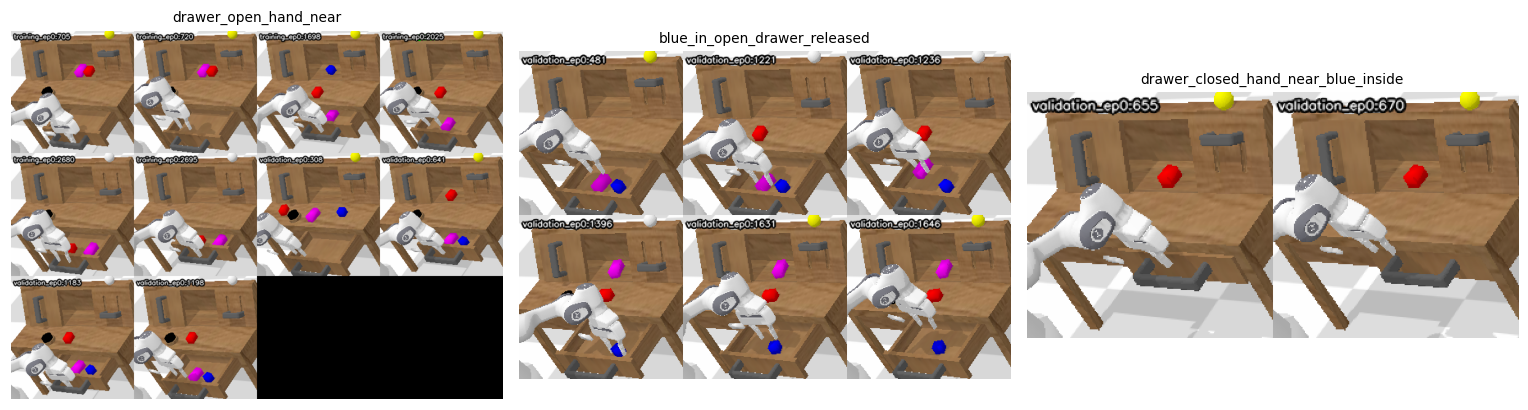

In [19]:
from PIL import Image
folder = "datasets/guidance_conditions/multigoal_drawer_block"
if os.path.isdir(folder):
    fig, axes = plt.subplots(1, 3, figsize = (14, 5))
    for ax, name in zip(axes, ["drawer_open_hand_near", "blue_in_open_drawer_released", "drawer_closed_hand_near_blue_inside"]):
        ax.imshow(Image.open(os.path.join(folder, f"{name}.png"))); ax.set_title(name, fontsize = 9); ax.axis("off")
    fig.tight_layout()

In [20]:
import h5py

def run_logs(folder):
    """The results json of each finished task of a run_experiments.py output folder, with the states of its rollouts."""
    logs = dict()
    for path in sorted(glob.glob(os.path.join(folder, "*", "*", "*_log.json"))):
        experiment, variant = path.split(os.sep)[-3:-1]
        with open(path) as f:
            log = json.load(f)
        rollouts = glob.glob(os.path.join(os.path.dirname(path), "*_rollout.hdf5"))
        if len(rollouts) == 1:
            with h5py.File(rollouts[0], "r") as file:
                log["states"] = [file[f"data/demo_{i}/next_obs/states"][()] for i in range(log["Num_Episode"])]
        logs[(experiment, variant)] = log
    return logs

logs = {**run_logs("results/multigoal_local_drawer"), **run_logs("results/multigoal_local_drawer_m150"), **run_logs("results/multigoal_local_block")}
print("Plans: plan_local_test_drawer.json (3 rollouts x 400 steps), plan_local_test_drawer_margin150.json (3 x 400), plan_local_test_block.json (2 x 600)")
lines = ["| experiment | variant | episodes | success | mean steps done | reached per step | DynaGuide moved on (too early / missed / mean delay) | minutes |", "|---|---|---|---|---|---|---|---|"]
for (experiment, variant), log in logs.items():
    switching = log.get("Switching", {})
    moved = "(no guidance)" if variant == "base_policy" else "(oracle)" if variant == "oracle" else \
        "; ".join(f"{name}: {s['switched']} ({s['too_early']} / {s['missed']} / {s['mean_delay']})" for name, s in switching.items())
    lines.append(f"| {experiment} | {variant} | {log['Num_Episode']} | {log['Num_Success']} | {log['Mean_Steps_Completed']:.2f} | {log['Step_Reach_Rate']} | {moved} | {log['Time_Episode']:.0f} |")
Markdown("\n".join(lines) if len(logs) > 0 else "No rollouts found yet, run the plans of section 1.5.")

Plans: plan_local_test_drawer.json (3 rollouts x 400 steps), plan_local_test_drawer_margin150.json (3 x 400), plan_local_test_block.json (2 x 600)


| experiment | variant | episodes | success | mean steps done | reached per step | DynaGuide moved on (too early / missed / mean delay) | minutes |
|---|---|---|---|---|---|---|---|
| drawer_open_close | base_policy | 3 | 0 | 0.67 | {'open_drawer': 0.6666666666666666, 'close_drawer': 0.0} | (no guidance) | 5 |
| drawer_open_close | latent | 3 | 1 | 0.67 | {'open_drawer': 0.3333333333333333, 'close_drawer': 0.3333333333333333} | open_drawer: 2 (1 / 0 / 9.0) | 13 |
| drawer_open_close | oracle | 3 | 1 | 1.00 | {'open_drawer': 0.6666666666666666, 'close_drawer': 0.3333333333333333} | (oracle) | 10 |
| drawer_open_close | latent_margin150 | 3 | 1 | 1.00 | {'open_drawer': 0.6666666666666666, 'close_drawer': 0.3333333333333333} | open_drawer: 1 (0 / 1 / 10.0) | 11 |
| drawer_block_close | latent | 2 | 0 | 1.00 | {'open_drawer': 1.0, 'blue_in_drawer': 0.0, 'close_drawer': 0.0} | open_drawer: 2 (0 / 0 / 108.0); blue_in_drawer: 0 (0 / 0 / None) | 14 |
| drawer_block_close | oracle | 2 | 0 | 1.00 | {'open_drawer': 1.0, 'blue_in_drawer': 0.0, 'close_drawer': 0.0} | (oracle) | 12 |

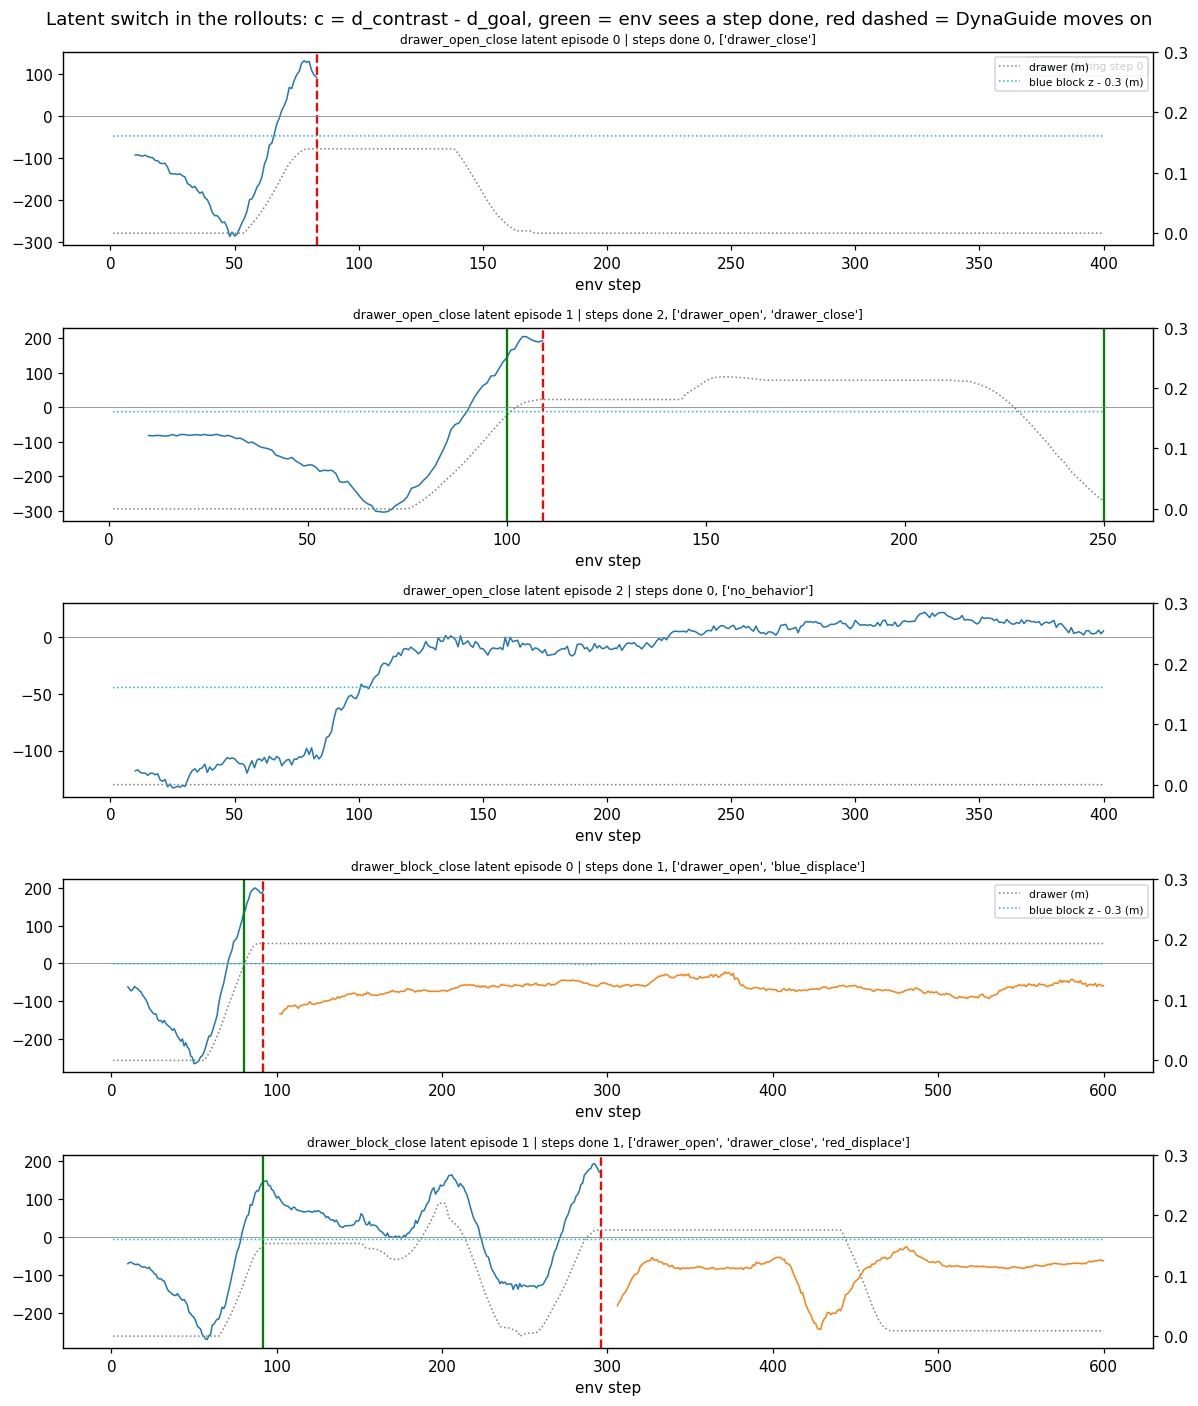

In [21]:
def episode_plot(log, number, ax, title):
    episode = log["Episode_Goal_Steps"][number]
    trace = np.array([row[:3] for row in log["Episode_Switches"][number]["trace"]], dtype = float) if log["Episode_Switches"][number]["trace"] else None
    if trace is not None and len(trace) > 0:
        for step in np.unique(trace[:, 1]).astype(int):
            part = trace[trace[:, 1] == step]
            ax.plot(part[:, 0], part[:, 2], lw = 1, label = f"c during step {step}")
    for step in episode["steps"]:
        if step["completed_at"] is not None:
            ax.axvline(step["completed_at"], color = "green", lw = 1.5)
    for switch in log["Episode_Switches"][number]["switches"]:
        ax.axvline(switch["t"], color = "red", lw = 1.5, ls = "--")
    ax.axhline(0, color = "gray", lw = 0.5)
    if "states" in log: # the drawer and the height of the blue block, as the env sees them
        states = log["states"][number]
        twin = ax.twinx()
        twin.plot(np.arange(1, len(states) + 1), states[:, 1], color = "tab:gray", lw = 1, ls = ":", label = "drawer (m)")
        twin.plot(np.arange(1, len(states) + 1), states[:, 14] - 0.3, color = "tab:cyan", lw = 1, ls = ":", label = "blue block z - 0.3 (m)")
        twin.set_ylim(-0.02, 0.3)
        if number == 0:
            twin.legend(fontsize = 7, loc = "upper right")
    ax.set_title(title + f" | steps done {episode['steps_completed']}, {episode['behaviors']}", fontsize = 8)
    ax.set_xlabel("env step")

latent = [(key, log) for key, log in logs.items() if key[1] == "latent"]
if len(latent) > 0:
    count = sum(len(log["Episode_Goal_Steps"]) for _, log in latent)
    fig, axes = plt.subplots(count, 1, figsize = (11, 2.6 * count), squeeze = False)
    row = 0
    for (experiment, variant), log in latent:
        for number in range(len(log["Episode_Goal_Steps"])):
            episode_plot(log, number, axes[row, 0], f"{experiment} {variant} episode {number}")
            row += 1
    axes[0, 0].legend(fontsize = 7)
    fig.suptitle("Latent switch in the rollouts: c = d_contrast - d_goal, green = env sees a step done, red dashed = DynaGuide moves on")
    fig.tight_layout()

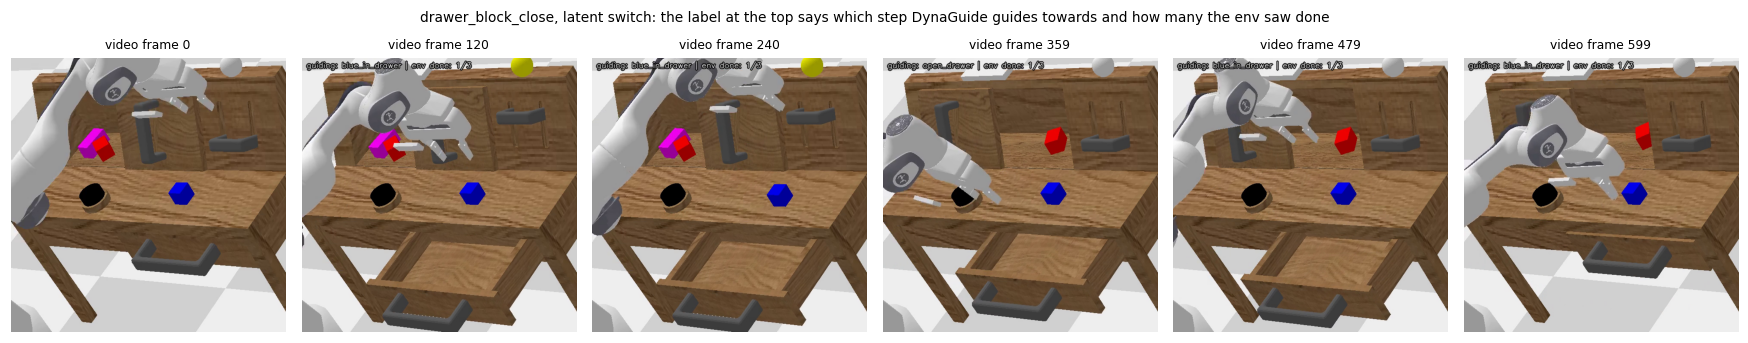

In [22]:
import imageio.v2 as imageio
def stills(video, count = 6):
    reader = imageio.get_reader(video)
    frames = [frame for frame in reader]
    picks = np.linspace(0, len(frames) - 1, count).round().astype(int)
    return [frames[i] for i in picks], picks

videos = [video for video in sorted(glob.glob("results/multigoal_local_*/*/latent/*.mp4"))
          if os.path.exists(os.path.join(os.path.dirname(video), "DONE"))] # a running task's video isn't complete yet
if len(videos) > 0:
    frames, picks = stills(videos[0], 6)
    fig, axes = plt.subplots(1, 6, figsize = (16, 3.2))
    for ax, frame, pick in zip(axes, frames, picks):
        ax.imshow(frame); ax.axis("off"); ax.set_title(f"video frame {pick}", fontsize = 8)
    fig.suptitle(f"{videos[0].split(os.sep)[-3]}, latent switch: the label at the top says which step DynaGuide guides towards and how many the env saw done", fontsize = 9)
    fig.tight_layout()

### What the rollouts show

These are 3 rollouts per variant for *open → close* and 2 for *open → block in → close*: a test that it works end to end, far too few to compare success rates. Episodes with the same number start from the same scene and robot pose in all variants of a task (the reset uses the seed); the policy's noise differs once the variants act differently.

**Everything runs together.** The plan runner, the multi-goal tracker, the guidance per step, the latent and oracle switches, replanning on a switch, the video label and the results json with `Switching` and `Episode_Switches` all worked without a crash in 16 rollouts.

**open → close (`drawer_open_close`):**

- Episode 1 succeeded with both switches. The latent one moved on at step 109, 9 steps after the env saw the drawer open (0.18 by then), and the close guidance then closed the drawer. That is a task a single goal can't do; the base policy didn't do it in any episode.
- Episode 2 did nothing in any variant within 400 steps (the base policy turned the switch on and off). The score `c` rose to about 0 and stayed there: the robot came near the drawer but didn't pull.
- Episode 0 is the informative one. The robot pulled the drawer to 0.14 and stopped there (in the oracle and margin-150 runs, it stayed there for about 35 steps before pulling on). For the camera that is open (the reset's "open" is 0.16); for the env it isn't (0.15 since your stricter thresholds). The latent switch saw a peak (`c` = 131) and moved on, the close guidance closed the drawer, and the env never counted the opening: **too early**. With the oracle, the open guidance went on, the robot pulled to 0.20 and the env counted it (step 117), but then the close guidance stalled at 0.07.
- **Margin 150** (`plan_local_test_drawer_margin150.json`) keeps the switch from moving on at 0.14, but in episode 0 the robot later reached 0.19 with only `c` = 123, so DynaGuide never moved on: **missed**. Under guidance, the level of `c` depends on the robot pose as much as on 0.14 against 0.19. No margin separates these two cases, so the default stays 30, where at least a switch happens.

**open → blue in → close (`drawer_block_close`):** this test ran while the drawer step still had margin 150 (each task's `config.json` records what it ran with). The drawer step worked in all 4 episodes: the env saw the drawer open at 80 and 92 (latent) and at 80 and 200 (oracle). The latent switch moved on at 92 (12 steps after the env) and at 296. That is **204 steps late**, another sign that margin 150 is too high under guidance. The block step never completed, neither with the latent nor with the oracle switch: the blue block was pushed (`blue_displace`) but not picked up and put in the drawer, and once the drawer was closed without it. Since the oracle fails the same way, **the bottleneck is the guidance of the block step, not the switch**. Its conditions are 6 frames from the debug set in the original image domain, against 16 to 32 rendered ones for the drawer.

**Conclusions from the rollouts:**

1. The design works: multi-step tasks, including contradictory ones (open, then close), run and can succeed, which single-goal guidance can't.
2. The latent switch behaves as calibrated where the behavior is clear. Its failure mode is a behavior that stops visually done but just short of the env's threshold. There, a wrong switch and a missing switch are the only options for any latent criterion.
3. The block steps need better conditions before multi-step block tasks can work, which led to sections 10 and 12.

## 12. One block, one scene: open → grip → release → close

The block steps of section 11 failed with the oracle too, so the problem was the guidance, not the switch. Their conditions had other blocks in other places, a scene unlike the reset, and too few distinct frames. This task removes those differences:

- **One scene for every reset and every condition:** door left, switch off, lights off, drawer closed, only the blue block, at the right front corner of the table (x 0.30, y −0.12, yaw 0). The red and pink blocks are hidden. The corner is where the fewest reset poses put the hand (3 to 5 % within 8 cm, against 25 % at `table_center`): from `table_center`, the base policy pushed the block aside before it went for the drawer (see below).
- **Four steps instead of three**, because the dynamics model predicts the end of the *current* segment, and the training segmentation cuts a segment when the hand touches a block. "Block in the drawer" is too far ahead to see from a hand that hasn't grasped yet, so the grasp is its own step.

**Why the block moved.** The first smoke test started the block at `table_center`. The base policy then lowered the hand next to the block, closed the gripper and swept the block to the right, the CALVIN "push block right" play motion, before it went for the drawer. Unguided base-policy rollouts, 10 per spot, 150 steps, same seeds:

| block at | block moved > 1 cm | drawer opened |
|---|---|---|
| `table_center` | 6 / 10 (up to 9.7 cm) | 0 / 10 |
| right front corner | 2 / 10 (up to 4 cm) | 2 / 10 |

The pull comes from the policy itself, not from the guidance.

| step | env checks | guidance conditions | switch contrast |
|---|---|---|---|
| `open_drawer` | `drawer_open` | `open_drawer` (4) | `open_drawer_contrast` (3) |
| `grip_blue` | blue `held` | `grip_blue` (8) | step 1's goal |
| `release_blue_in_drawer` | drawer open, blue in the drawer and not held | `release_blue_in_drawer` (10) | step 2's goal |
| `close_drawer` | `drawer_close`, blue in the drawer | `close_drawer` (3) | step 3's goal |

The task file is `calvin_exp_configs_examples/tasks/single_block_drawer.json`; `make_task.py` makes its conditions and its config, see section 1.3. The first version of this task used lifted poses (`blue_lift`, 3 cm up) as its second step. It now grips, because a grip is what ends a segment in the training data (section 10).

The margin of the block steps is the default 30. The calibration of section 8 covered only the drawer, door and switch, so the switch behavior on the block steps is new. The workstation script is `run_single_block_drawer.bat` (section 1.7).

## 13. Why the robot doesn't grip: a check of DynaGuide itself

In the pipeline test (`dynaguide_scripts/test_task_pipeline.sh`, 2 rollouts per variant), the guided robot never gripped the block. Two causes could be ruled out from that data:
- **The switch:** latent and oracle ran identically, because no grip happened, so no switch fired.
- **The env not seeing a grip:** the hand never came within 5 cm of the block; "held" needs it within 4 cm with the gripper closed on it.

Three tests on the MacBook, in the task's scene (data in `results/grip_diagnosis`):

**1. Can the base policy grip?** Unguided, 10 rollouts of 150 steps per block spot:

| block at | gripped |
|---|---|
| right corner (the task) | 2/10 |
| center | 1/10 |
| left | 0/10 |

It can, but rarely. Pushing the block, pressing the button and closing the drawer are more common.

**2. How much does the block count in the embedding?** The 8 grip conditions, rendered again with the same robot:

| distance from a grip condition to | DINO only | guidance space |
|---|---|---|
| block removed | 133 | 107 |
| block back on the table, not gripped | 110 | 88 |
| nearest other grip condition (other arm pose) | 221 | 146 |
| contrast (hand at the drawer handle) | 558 | 420 |

Reaching the arm pose earns about 80 % of the way; gripping adds the rest.

**3. Does the signal point toward gripping?** The 30 base rollouts went through the guidance's own computation: the prediction for the chunk the robot really executed, and its soft-min distance to the grip conditions:

| compared with the 51 chunks that led to a grip (median 133) | median | AUC |
|---|---|---|
| hand far from the block | 287 | 0.94 |
| hand within 8 cm of the block, no grip | 177 | 0.79 |

**Summary.** The direction is right and strong for "go to the block", but weak for "close the gripper on it". With a policy that grips in about 20 % of rollouts, scale 1.5 may simply be too little.

**The deciding test** runs on the workstation, with `dynaguide_scripts/run_grip_scale_sweep.bat` (section 1.7):
- **What runs:** the grip-only task (`tasks/blue_grip_table_right.json`), with the base policy and guided at scale 1.5, 3 and 5. Each runs 20 rollouts of 200 steps, all from the same start scenes (`multigoal/plan_grip_scale_sweep.json`).
- **If guided runs grip clearly more often than the base policy**, and more with a higher scale: the guidance works and only needs strength.
- **If they stay at the base rate:** gripping is a limit of DINO + this dynamics model + this policy, and multi-goal guidance shouldn't be tuned around it.

## 14. Limitations and next steps

- **Few rollouts so far.** Sections 11 and 12 show that it works end to end, not how well. The workstation plans (section 1.7) are the evaluation; the oracle vs. latent comparison shows how much the switch costs.
- **Gripping is the weak part.** The block conditions are now made in the scene of each task (section 10), but the guidance separates a grip only weakly from a hand next to the block, and the policy grips rarely (section 13). The grip scale sweep decides whether this can be tuned or is a limit of the method.
- **The switch is tested offline so far** (section 8). The rollouts of `run_goal_switch.bat` and `run_goal_switch_patches.bat` are the first test of the new criteria while they really steer.
- **Grips still use the older switch.** A grip changes nothing that stays in place, so there is no object change to look for (section 7). Releases use `patches`, tested only offline (section 8).
- **A half-done joint that comes to rest** above the margin counts as done, e.g. a drawer that stops at 0.12 of 0.15. The tables of section 8 count these as *on the way*.
- **Steps whose goal already holds at their start** are skipped by the `change` criterion after `patience` checks. The env counts the step only if the behavior happens during it, so such an episode can't succeed.
- The idea in `Complex tasks ideas.md` of weighting steps (100 %, 75 %, …) is a different approach: all steps at once with priorities. With the sequence, each step gets the full guidance, and contradictory goals (open, then close) become possible.